# Python机器学习基础教程 ch02：监督学习

对应笔记 [ch02.md](../ch02.md)。本 notebook 是**分节跟随代码**：小节结构与笔记一致，完整讲解、原书插图与“坑与陷阱”请看笔记页面。

运行环境：`machinelearn`（Python 3.10 / scikit-learn 1.7 / pandas 2.3 / mglearn，mglearn 已打 boston 本地数据补丁）。原书 0.19 时代 API 的适配处在代码注释中以 **版本适配** 标出，与笔记中的“版本差异” admonition 一一对应。

In [1]:
# ===== 公共设置（notebook 版新增；原书在 Jupyter 全局环境中运行）=====
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import mglearn

# 兜底：nbclient/nbconvert 实跑时 inline 后端的 flush_figures 钩子未注册，
# 图会留在内存不进输出——这里手动补一个“每个 cell 结束时把打开的图显示出来”
import IPython
_ip = IPython.get_ipython()
if _ip is not None:
    def _flush_figs():
        if plt.get_fignums():
            plt.show()
    _ip.events.register("post_execute", _flush_figs)

print("sklearn", sklearn.__version__, "| pandas", pd.__version__,
      "| numpy", np.__version__)

# 版本适配：Windows 下 graphviz 二进制所在目录（conda 环境 Library/bin）；
# 其他环境已装 Graphviz 的话无需此行
import os
_gv = r"C:\Anocanda\envs\machinelearn\Library\bin"
if os.path.isdir(_gv):
    os.environ["PATH"] = os.environ.get("PATH", "") + os.pathsep + _gv

sklearn 1.7.0 | pandas 2.3.3 | numpy 2.2.6


**本章解决**：监督学习（supervised learning）怎么落地——先用"买船预测"的例子讲清泛化、过拟合与欠拟合这一全书主线，再把 scikit-learn 里最常用的 8 类模型逐个讲透：kNN、线性模型（OLS/Ridge/Lasso/LogisticRegression/LinearSVC）、朴素贝叶斯、决策树、随机森林、梯度提升、核 SVM、神经网络，最后教你拿到 `decision_function` 和 `predict_proba` 两把"不确定度"的尺子。
第 1 章用鸢尾花走通了"训练—评估"流程；本章是它的算法篇展开，也是全书最长的一章，可以当参考手册反复回查。下一章转向无监督学习与预处理。

## 2.1 分类与回归

监督机器学习问题主要有两种：**分类（classification）** 与 **回归（regression）**。

## 2.2 泛化、过拟合与欠拟合

在监督学习中，我们想在训练数据上构建模型，然后对没见过的新数据（与训练集具有相同的特性）做出准确预测。如果一个模型能够对没见过的数据做出准确预测，我们就说它能够从训练集**泛化（generalize）** 到测试集。我们想要构建一个泛化精度尽可能高的模型。

### 模型复杂度与数据集大小的关系

模型复杂度与训练数据集中**输入的变化**密切相关：数据集中数据点的变化范围越大，在不发生过拟合的前提下可以使用的模型就越复杂。通常收集更多数据点可以有更大的变化范围，所以更大的数据集可以用来构建更复杂的模型。但**仅复制相同的数据点或收集非常相似的数据是无济于事的**。

## 2.3 监督学习算法

本节介绍最常用的机器学习算法：它们如何从数据中学习、如何预测、复杂度如何变化、优缺点是什么、最适用于哪类数据，以及最重要的参数和选项的含义。许多算法都有分类和回归两种形式，两种都会讲到。没有必要通读每个算法的详细描述——本章可以当参考指南，不确定某个算法怎么工作时回来查。

### 2.3.1 一些样本数据集

我们用一些数据集来说明不同算法：一部分是小型模拟数据集，用来强调算法的某个特定方面；另一部分是现实世界的大型数据集。

X.shape: (26, 2)


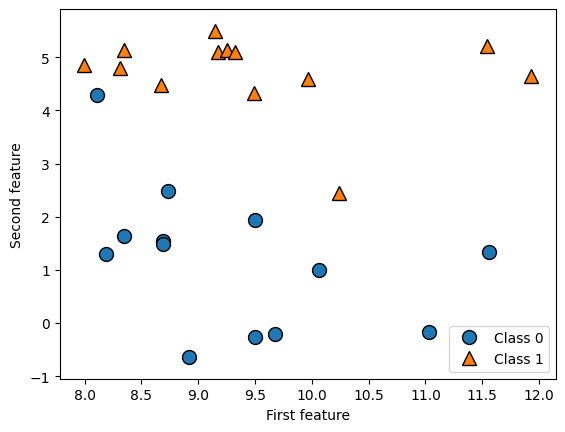

In [2]:
# ===== 书 2.3.1 节：forge 数据集散点图 =====
# 生成数据集
X, y = mglearn.datasets.make_forge()
# 数据集绘图：以第一个特征为 x 轴、第二个特征为 y 轴，颜色和形状对应类别
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
plt.legend(["Class 0", "Class 1"], loc=4)
plt.xlabel("First feature")
plt.ylabel("Second feature")
print("X.shape: {}".format(X.shape))

Text(0, 0.5, 'Target')

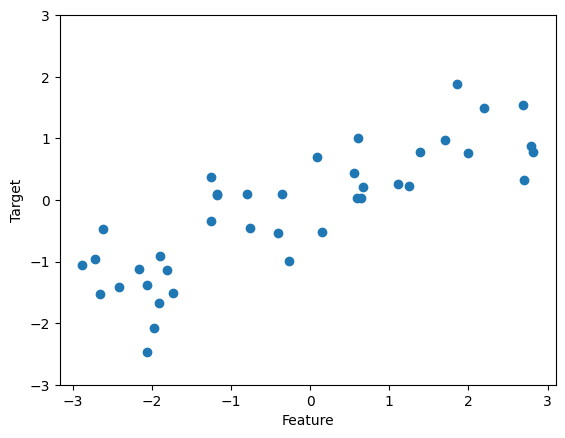

In [3]:
# ===== 书 2.3.1 节：wave 数据集图像 =====
X, y = mglearn.datasets.make_wave(n_samples=40)
plt.plot(X, y, 'o')
plt.ylim(-3, 3)
plt.xlabel("Feature")
plt.ylabel("Target")

In [4]:
# ===== 书 2.3.1 节：乳腺癌数据集 =====
from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer()
print("cancer.keys(): \n{}".format(cancer.keys()))
print("Shape of cancer data: {}".format(cancer.data.shape))
print("Sample counts per class:\n{}".format(
      {n: v for n, v in zip(cancer.target_names, np.bincount(cancer.target))}))
print("Feature names:\n{}".format(cancer.feature_names))

cancer.keys(): 
dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])
Shape of cancer data: (569, 30)
Sample counts per class:
{np.str_('malignant'): np.int64(212), np.str_('benign'): np.int64(357)}
Feature names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']


In [5]:
# ===== 书 2.3.1 节：波士顿房价与扩展特征 =====
from mglearn.datasets import load_boston  # 版本适配：sklearn≥1.2 移除 load_boston，改用 mglearn 内置等价加载（本地缓存）
boston = load_boston()
print("Data shape: {}".format(boston.data.shape))        # (506, 13)

X, y = mglearn.datasets.load_extended_boston()
print("X.shape: {}".format(X.shape))                     # (506, 104)

Data shape: (506, 13)
X.shape: (506, 104)


### 2.3.2 k 近邻

k-NN 算法可以说是最简单的机器学习算法：构建模型只需要保存训练数据集。想要对新数据点做出预测，算法在训练集中找到最近的数据点——它的"最近邻"。

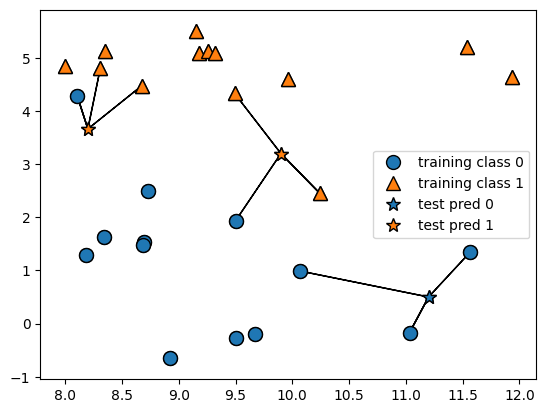

In [6]:
# ===== 书 2.3.2 节：单一近邻与 3 近邻的预测演示 =====
mglearn.plots.plot_knn_classification(n_neighbors=1)
mglearn.plots.plot_knn_classification(n_neighbors=3)

In [7]:
# ===== 书 2.3.2 节：KNeighborsClassifier 标准流程 =====
from sklearn.model_selection import train_test_split
X, y = mglearn.datasets.make_forge()

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

from sklearn.neighbors import KNeighborsClassifier
clf = KNeighborsClassifier(n_neighbors=3)   # 实例化：可设定参数，如邻居个数

clf.fit(X_train, y_train)   # 拟合：对 kNN 来说就是保存数据集，供预测时算距离

print("Test set predictions: {}".format(clf.predict(X_test)))
print("Test set accuracy: {:.2f}".format(clf.score(X_test, y_test)))

Test set predictions: [1 0 1 0 1 0 0]
Test set accuracy: 0.86


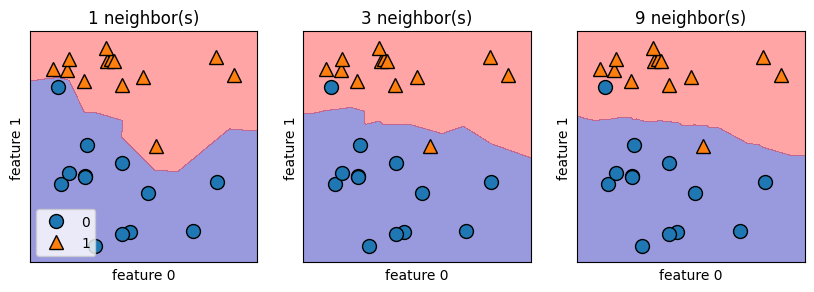

In [8]:
# ===== 书 2.3.2 节：不同 n_neighbors 值的决策边界 =====
fig, axes = plt.subplots(1, 3, figsize=(10, 3))

for n_neighbors, ax in zip([1, 3, 9], axes):
    # fit 方法返回对象本身，所以可以把实例化和拟合放在一行代码中
    clf = KNeighborsClassifier(n_neighbors=n_neighbors).fit(X, y)
    mglearn.plots.plot_2d_separator(clf, X, fill=True, eps=0.5, ax=ax, alpha=.4)
    mglearn.discrete_scatter(X[:, 0], X[:, 1], y, ax=ax)
    ax.set_title("{} neighbor(s)".format(n_neighbors))
    ax.set_xlabel("feature 0")
    ax.set_ylabel("feature 1")
axes[0].legend(loc=3)

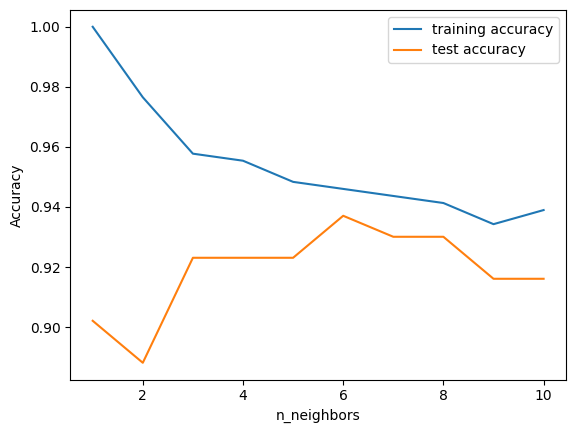

In [9]:
# ===== 书 2.3.2 节：乳腺癌数据集上扫描 n_neighbors =====
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, stratify=cancer.target, random_state=66)

training_accuracy = []
test_accuracy = []
# n_neighbors 取值从 1 到 10
neighbors_settings = range(1, 11)

for n_neighbors in neighbors_settings:
    # 构建模型
    clf = KNeighborsClassifier(n_neighbors=n_neighbors)
    clf.fit(X_train, y_train)
    # 记录训练集精度
    training_accuracy.append(clf.score(X_train, y_train))
    # 记录泛化精度
    test_accuracy.append(clf.score(X_test, y_test))

plt.plot(neighbors_settings, training_accuracy, label="training accuracy")
plt.plot(neighbors_settings, test_accuracy, label="test accuracy")
plt.ylabel("Accuracy")
plt.xlabel("n_neighbors")
plt.legend()

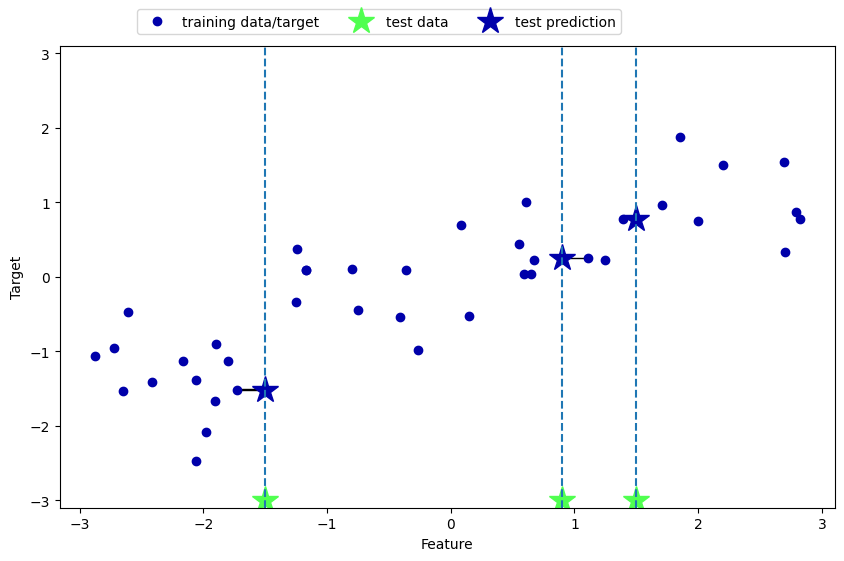

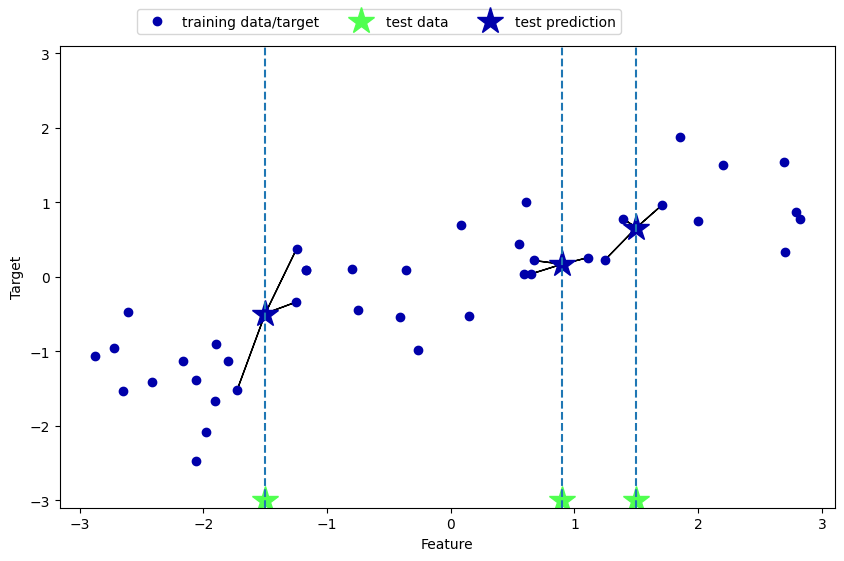

In [10]:
# ===== 书 2.3.2 节：k 近邻回归演示（图 2-8 / 图 2-9） =====
mglearn.plots.plot_knn_regression(n_neighbors=1)
mglearn.plots.plot_knn_regression(n_neighbors=3)

In [11]:
# ===== 书 2.3.2 节：KNeighborsRegressor =====
from sklearn.neighbors import KNeighborsRegressor

X, y = mglearn.datasets.make_wave(n_samples=40)

# 将 wave 数据集分为训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)

# 模型实例化，并将邻居个数设为 3
reg = KNeighborsRegressor(n_neighbors=3)
# 利用训练数据和训练目标值来拟合模型
reg.fit(X_train, y_train)

print("Test set predictions:\n{}".format(reg.predict(X_test)))
print("Test set R^2: {:.2f}".format(reg.score(X_test, y_test)))

Test set predictions:
[-0.05396539  0.35686046  1.13671923 -1.89415682 -1.13881398 -1.63113382
  0.35686046  0.91241374 -0.44680446 -1.13881398]
Test set R^2: 0.83


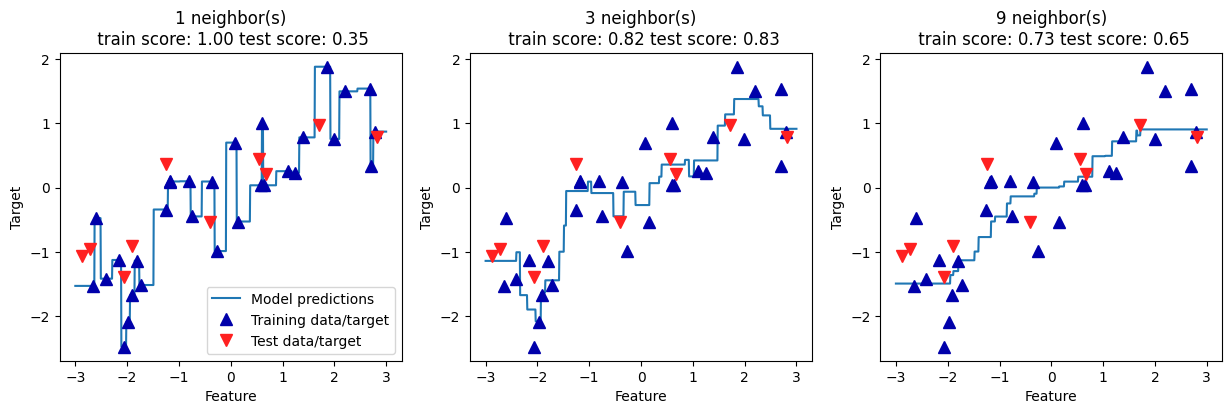

In [12]:
# ===== 书 2.3.2 节：不同 n_neighbors 的 kNN 回归对比 =====
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
# 创建 1000 个数据点，在 -3 和 3 之间均匀分布
line = np.linspace(-3, 3, 1000).reshape(-1, 1)
for n_neighbors, ax in zip([1, 3, 9], axes):
    # 利用 1 个、3 个或 9 个邻居分别进行预测
    reg = KNeighborsRegressor(n_neighbors=n_neighbors)
    reg.fit(X_train, y_train)
    ax.plot(line, reg.predict(line))
    ax.plot(X_train, y_train, '^', c=mglearn.cm2(0), markersize=8)
    ax.plot(X_test, y_test, 'v', c=mglearn.cm2(1), markersize=8)
    ax.set_title(
        "{} neighbor(s)\n train score: {:.2f} test score: {:.2f}".format(
            n_neighbors, reg.score(X_train, y_train),
            reg.score(X_test, y_test)))
    ax.set_xlabel("Feature")
    ax.set_ylabel("Target")
axes[0].legend(["Model predictions", "Training data/target",
                "Test data/target"], loc="best")

### 2.3.3 线性模型

线性模型（linear models）在实践中广泛使用，几十年来被大量研究，可以追溯到一百多年前。线性模型利用输入特征的**线性函数（linear function）** 进行预测。

w[0]: 0.393906  b: -0.031804


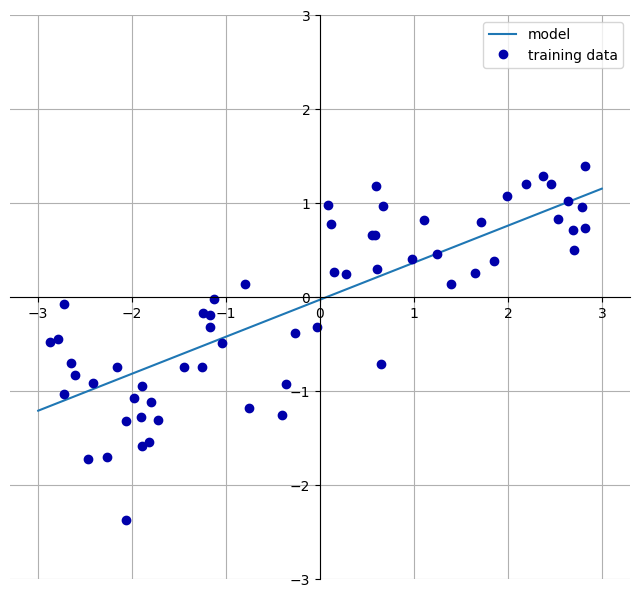

In [13]:
# ===== 书 2.3.3 节：线性回归在 wave 数据集上 =====
mglearn.plots.plot_linear_regression_wave()

In [14]:
# ===== 书 2.3.3 节：LinearRegression 在 wave 数据集上 =====
from sklearn.linear_model import LinearRegression
X, y = mglearn.datasets.make_wave(n_samples=60)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

lr = LinearRegression().fit(X_train, y_train)

# “斜率”参数 w（权重/系数）保存在 coef_，偏移 b 保存在 intercept_
print("lr.coef_: {}".format(lr.coef_))
print("lr.intercept_: {}".format(lr.intercept_))
print("Training set score: {:.2f}".format(lr.score(X_train, y_train)))
print("Test set score: {:.2f}".format(lr.score(X_test, y_test)))

lr.coef_: [0.39390555]
lr.intercept_: -0.031804343026759746
Training set score: 0.67
Test set score: 0.66


In [15]:
# ===== 书 2.3.3 节：LinearRegression 在扩展波士顿房价数据集上 =====
X, y = mglearn.datasets.load_extended_boston()

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=0)
lr = LinearRegression().fit(X_train, y_train)
print("Training set score: {:.2f}".format(lr.score(X_train, y_train)))
print("Test set score: {:.2f}".format(lr.score(X_test, y_test)))

Training set score: 0.95
Test set score: 0.61


In [16]:
# ===== 书 2.3.3 节：Ridge 与 alpha 参数 =====
from sklearn.linear_model import Ridge

ridge = Ridge().fit(X_train, y_train)      # 默认 alpha=1.0
print("Training set score: {:.2f}".format(ridge.score(X_train, y_train)))
print("Test set score: {:.2f}".format(ridge.score(X_test, y_test)))

ridge10 = Ridge(alpha=10).fit(X_train, y_train)
print("alpha=10:  train {:.2f} / test {:.2f}".format(
      ridge10.score(X_train, y_train), ridge10.score(X_test, y_test)))

ridge01 = Ridge(alpha=0.1).fit(X_train, y_train)
print("alpha=0.1: train {:.2f} / test {:.2f}".format(
      ridge01.score(X_train, y_train), ridge01.score(X_test, y_test)))

Training set score: 0.89
Test set score: 0.75
alpha=10:  train 0.79 / test 0.64
alpha=0.1: train 0.93 / test 0.77


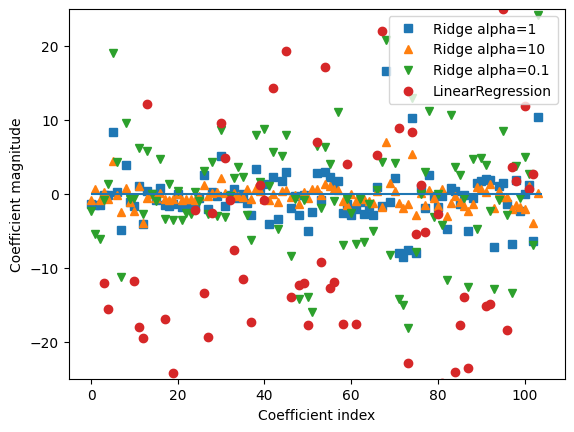

In [17]:
# ===== 书 2.3.3 节：不同 alpha 的岭回归与线性回归系数比较 =====
plt.plot(ridge.coef_, 's', label="Ridge alpha=1")
plt.plot(ridge10.coef_, '^', label="Ridge alpha=10")
plt.plot(ridge01.coef_, 'v', label="Ridge alpha=0.1")

plt.plot(lr.coef_, 'o', label="LinearRegression")
plt.xlabel("Coefficient index")
plt.ylabel("Coefficient magnitude")
plt.hlines(0, 0, len(lr.coef_))
plt.ylim(-25, 25)
plt.legend()

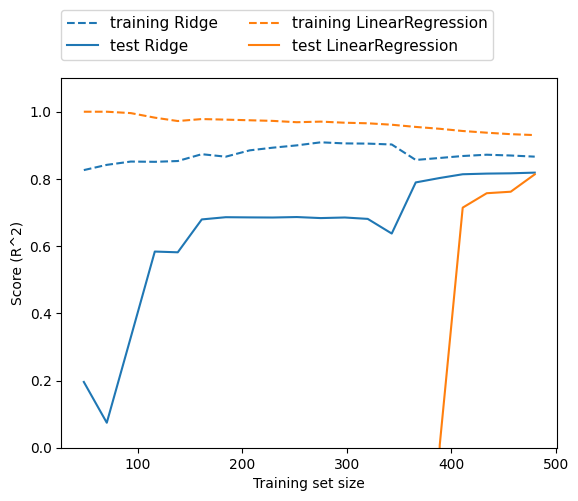

In [18]:
# ===== 书 2.3.3 节：岭回归与线性回归的学习曲线 =====
mglearn.plots.plot_ridge_n_samples()

In [19]:
# ===== 书 2.3.3 节：Lasso 与 alpha =====
from sklearn.linear_model import Lasso

lasso = Lasso().fit(X_train, y_train)      # 默认 alpha=1.0
print("Training set score: {:.2f}".format(lasso.score(X_train, y_train)))
print("Test set score: {:.2f}".format(lasso.score(X_test, y_test)))
print("Number of features used: {}".format(np.sum(lasso.coef_ != 0)))

# 减小 alpha 并增大 max_iter（否则会警告应该增大 max_iter）
lasso001 = Lasso(alpha=0.01, max_iter=100000).fit(X_train, y_train)
print("alpha=0.01:  train {:.2f} / test {:.2f}, features used {}".format(
      lasso001.score(X_train, y_train), lasso001.score(X_test, y_test),
      np.sum(lasso001.coef_ != 0)))

lasso00001 = Lasso(alpha=0.0001, max_iter=100000).fit(X_train, y_train)
print("alpha=0.0001: train {:.2f} / test {:.2f}, features used {}".format(
      lasso00001.score(X_train, y_train), lasso00001.score(X_test, y_test),
      np.sum(lasso00001.coef_ != 0)))

Training set score: 0.29
Test set score: 0.21
Number of features used: 4
alpha=0.01:  train 0.90 / test 0.77, features used 33


alpha=0.0001: train 0.95 / test 0.64, features used 96


Text(0, 0.5, 'Coefficient magnitude')

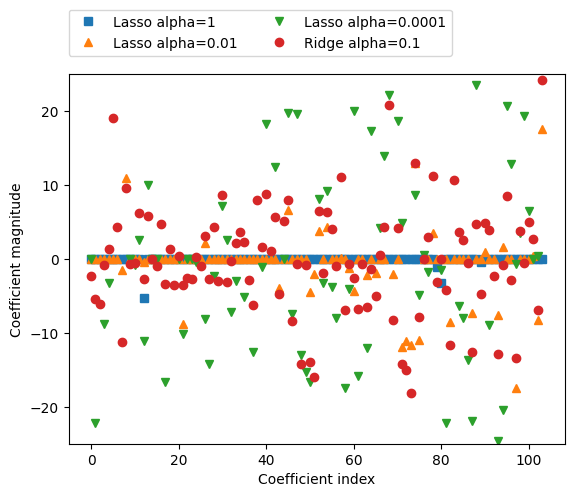

In [20]:
# ===== 书 2.3.3 节：不同 alpha 的 lasso 与岭回归系数比较（图 2-14） =====
plt.plot(lasso.coef_, 's', label="Lasso alpha=1")
plt.plot(lasso001.coef_, '^', label="Lasso alpha=0.01")
plt.plot(lasso00001.coef_, 'v', label="Lasso alpha=0.0001")

plt.plot(ridge01.coef_, 'o', label="Ridge alpha=0.1")
plt.legend(ncol=2, loc=(0, 1.05))
plt.ylim(-25, 25)
plt.xlabel("Coefficient index")
plt.ylabel("Coefficient magnitude")

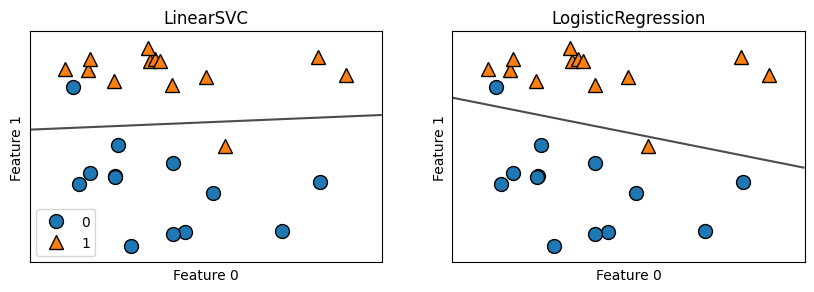

In [21]:
# ===== 书 2.3.3 节：LinearSVC 与 LogisticRegression 在 forge 上 =====
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

X, y = mglearn.datasets.make_forge()

fig, axes = plt.subplots(1, 2, figsize=(10, 3))

for model, ax in zip([LinearSVC(), LogisticRegression()], axes):
    clf = model.fit(X, y)
    mglearn.plots.plot_2d_separator(clf, X, fill=False, eps=0.5,
                                    ax=ax, alpha=.7)
    mglearn.discrete_scatter(X[:, 0], X[:, 1], y, ax=ax)
    ax.set_title("{}".format(clf.__class__.__name__))
    ax.set_xlabel("Feature 0")
    ax.set_ylabel("Feature 1")
axes[0].legend()

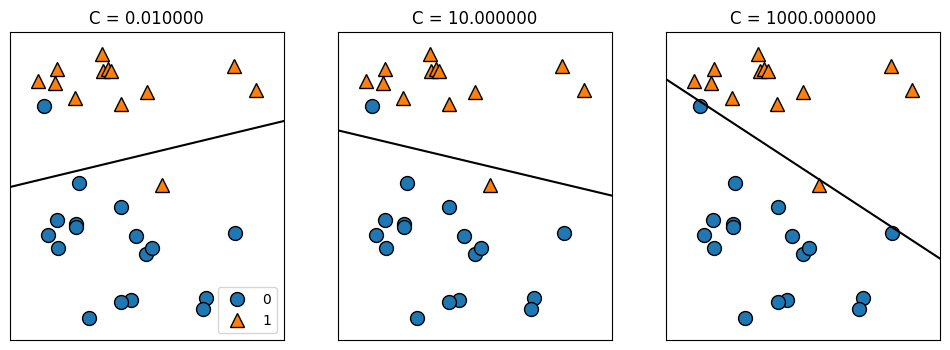

In [22]:
# ===== 书 2.3.3 节：不同 C 值的线性 SVM =====
mglearn.plots.plot_linear_svc_regularization()

In [23]:
# ===== 书 2.3.3 节：LogisticRegression 在乳腺癌数据集上 =====
from sklearn.datasets import load_breast_cancer
cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, stratify=cancer.target, random_state=42)

logreg = LogisticRegression().fit(X_train, y_train)      # 默认 C=1
print("C=1:    train {:.3f} / test {:.3f}".format(
      logreg.score(X_train, y_train), logreg.score(X_test, y_test)))

logreg100 = LogisticRegression(C=100).fit(X_train, y_train)
print("C=100:  train {:.3f} / test {:.3f}".format(
      logreg100.score(X_train, y_train), logreg100.score(X_test, y_test)))

logreg001 = LogisticRegression(C=0.01).fit(X_train, y_train)
print("C=0.01:  train {:.3f} / test {:.3f}".format(
      logreg001.score(X_train, y_train), logreg001.score(X_test, y_test)))

C=1:    train 0.946 / test 0.958
C=100:  train 0.948 / test 0.958
C=0.01:  train 0.934 / test 0.930


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\linear_model\_logistic.py:470: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Plea

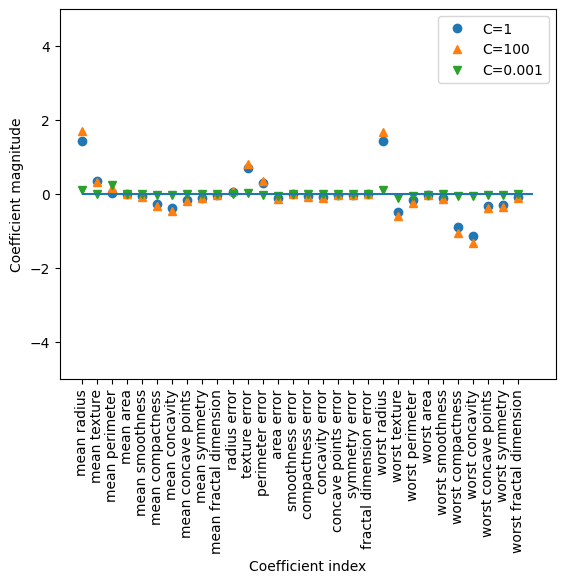

In [24]:
# ===== 书 2.3.3 节：不同 C 值的系数（图 2-17） =====
plt.plot(logreg.coef_.T, 'o', label="C=1")
plt.plot(logreg100.coef_.T, '^', label="C=100")
plt.plot(logreg001.coef_.T, 'v', label="C=0.001")
plt.xticks(range(cancer.data.shape[1]), cancer.feature_names, rotation=90)
plt.hlines(0, 0, cancer.data.shape[1])
plt.ylim(-5, 5)
plt.xlabel("Coefficient index")
plt.ylabel("Coefficient magnitude")
plt.legend()

Training accuracy of l1 logreg with C=0.001: 0.91
Test accuracy of l1 logreg with C=0.001: 0.92


Training accuracy of l1 logreg with C=1.000: 0.96
Test accuracy of l1 logreg with C=1.000: 0.96


Training accuracy of l1 logreg with C=100.000: 0.99
Test accuracy of l1 logreg with C=100.000: 0.98


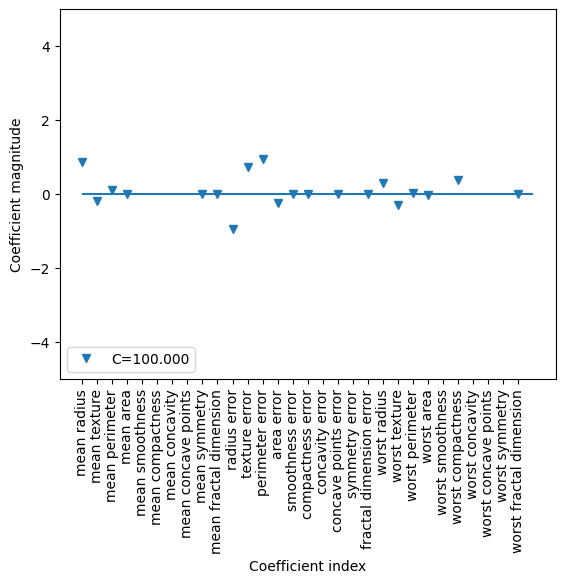

In [25]:
# ===== 书 2.3.3 节：L1 惩罚的 Logistic 回归（图 2-18） =====
for C, marker in zip([0.001, 1, 100], ['o', '^', 'v']):
    lr_l1 = LogisticRegression(C=C, penalty="l1", solver="liblinear").fit(X_train, y_train)  # 版本适配：l1 罚需 solver="liblinear"/"saga"
    print("Training accuracy of l1 logreg with C={:.3f}: {:.2f}".format(
          C, lr_l1.score(X_train, y_train)))
    print("Test accuracy of l1 logreg with C={:.3f}: {:.2f}".format(
          C, lr_l1.score(X_test, y_test)))

plt.plot(lr_l1.coef_.T, marker, label="C={:.3f}".format(C))
plt.xticks(range(cancer.data.shape[1]), cancer.feature_names, rotation=90)
plt.hlines(0, 0, cancer.data.shape[1])
plt.xlabel("Coefficient index")
plt.ylabel("Coefficient magnitude")
plt.ylim(-5, 5)
plt.legend(loc=3)

Coefficient shape:  (3, 2)
Intercept shape:  (3,)


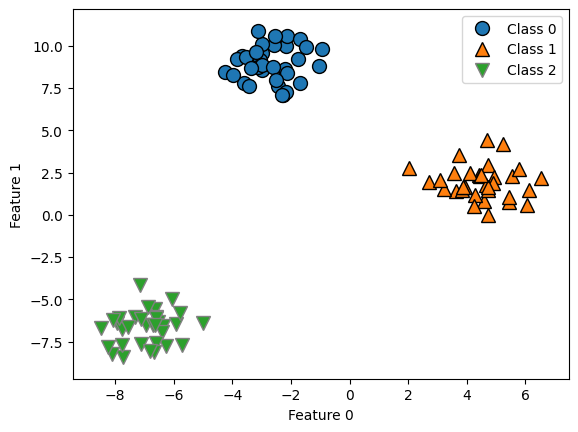

In [26]:
# ===== 书 2.3.3 节：三分类玩具数据集与 LinearSVC =====
from sklearn.datasets import make_blobs

X, y = make_blobs(random_state=42)
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.legend(["Class 0", "Class 1", "Class 2"])

linear_svm = LinearSVC().fit(X, y)
print("Coefficient shape: ", linear_svm.coef_.shape)     # (3, 2)
print("Intercept shape: ", linear_svm.intercept_.shape)  # (3,)

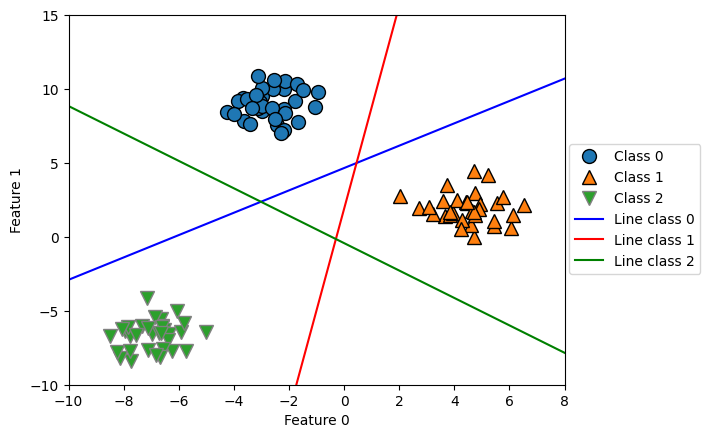

In [27]:
# ===== 书 2.3.3 节：画出每个类别的决策直线 =====
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
line = np.linspace(-15, 15)
for coef, intercept, color in zip(linear_svm.coef_, linear_svm.intercept_,
                                  ['b', 'r', 'g']):
    plt.plot(line, -(line * coef[0] + intercept) / coef[1], c=color)
plt.ylim(-10, 15)
plt.xlim(-10, 8)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")
plt.legend(['Class 0', 'Class 1', 'Class 2', 'Line class 0', 'Line class 1',
            'Line class 2'], loc=(1.01, 0.3))

Text(0, 0.5, 'Feature 1')

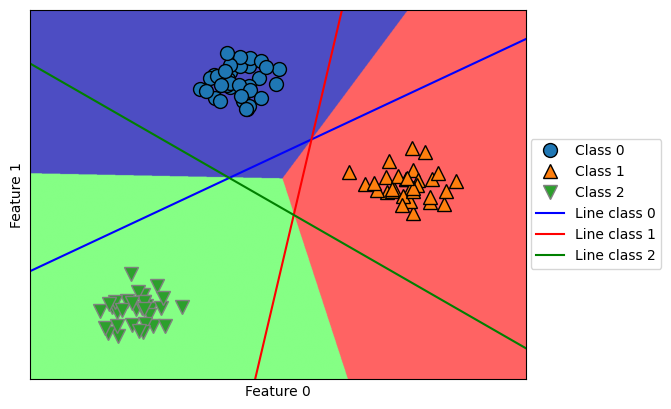

In [28]:
# ===== 书 2.3.3 节：完整的多分类决策边界 =====
mglearn.plots.plot_2d_classification(linear_svm, X, fill=True, alpha=.7)
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
line = np.linspace(-15, 15)
for coef, intercept, color in zip(linear_svm.coef_, linear_svm.intercept_,
                                  ['b', 'r', 'g']):
    plt.plot(line, -(line * coef[0] + intercept) / coef[1], c=color)
plt.legend(['Class 0', 'Class 1', 'Class 2', 'Line class 0', 'Line class 1',
            'Line class 2'], loc=(1.01, 0.3))
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

### 2.3.4 朴素贝叶斯分类器

朴素贝叶斯分类器与线性模型非常相似，但训练速度往往更快。代价是泛化能力通常比线性分类器（如 LogisticRegression 和 LinearSVC）稍差。它高效的原因在于：**通过单独查看每个特征来学习参数**，从每个特征中收集简单的类别统计数据。

In [29]:
# ===== 书 2.3.4 节：BernoulliNB 统计的非零元素计数 =====
X = np.array([[0, 1, 0, 1],
              [1, 0, 1, 1],
              [0, 0, 0, 1],
              [1, 0, 1, 0]])
y = np.array([0, 1, 0, 1])

counts = {}
for label in np.unique(y):
    # 对每个类别进行遍历
    # 计算（求和）每个特征中 1 的个数
    counts[label] = X[y == label].sum(axis=0)
print("Feature counts:\n{}".format(counts))

Feature counts:
{np.int64(0): array([0, 1, 0, 2]), np.int64(1): array([2, 0, 2, 1])}


### 2.3.5 决策树

**决策树（decision tree）** 广泛用于分类和回归任务。本质上，它从一层层的 if/else 问题中学习并得出结论，类似"20 Questions"游戏：想区分熊、鹰、企鹅和海豚四种动物，先用尽量少的是/否问题锁定答案——先问"有没有羽毛"（把候选缩到两种），有羽毛再问"会不会飞"区分鹰和企鹅，没羽毛则问"有没有鳍"区分海豚和熊。这一系列问题就是一棵决策树（图 2-22）：

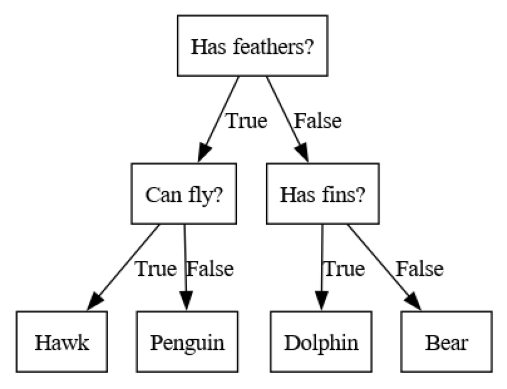

In [30]:
# ===== 书 2.3.5 节：动物分类决策树示意 =====
mglearn.plots.plot_animal_tree()

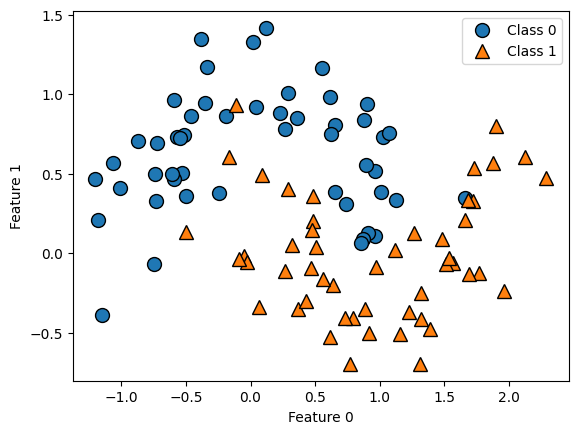

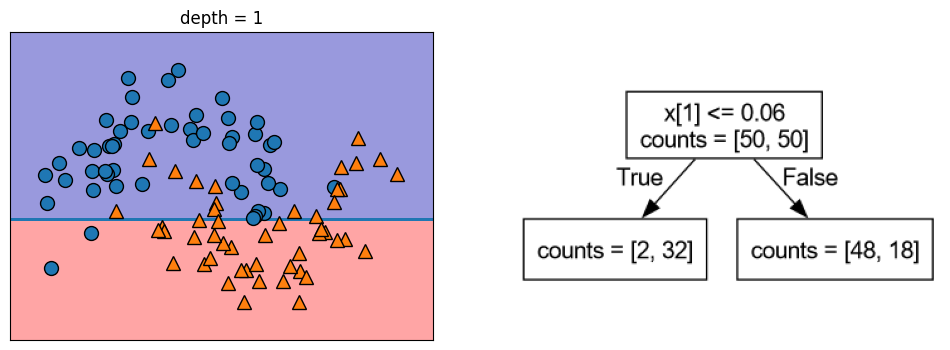

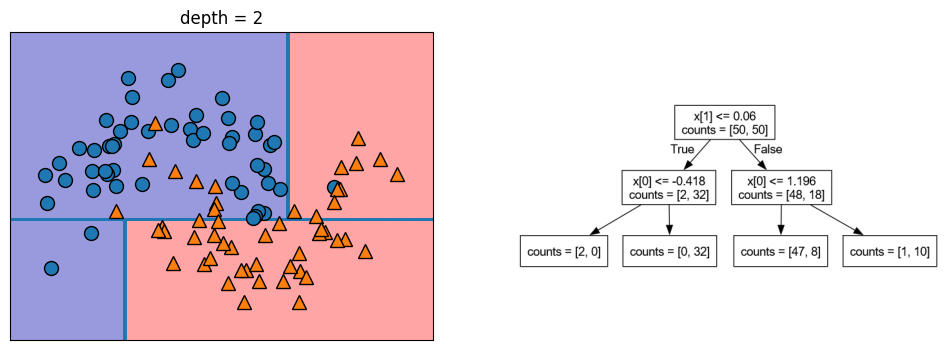

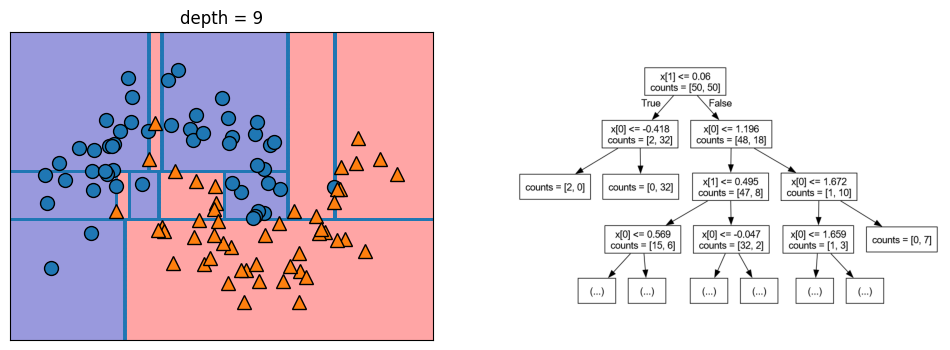

In [31]:
# ===== 书 2.3.5 节：逐层展示决策树的构造过程（生成图 2-24～图 2-26） =====
mglearn.plots.plot_tree_progressive()

In [32]:
# ===== 书 2.3.5 节：未剪枝与 max_depth=4 的决策树 =====
from sklearn.tree import DecisionTreeClassifier

cancer = load_breast_cancer()
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, stratify=cancer.target, random_state=42)

tree = DecisionTreeClassifier(random_state=0)
tree.fit(X_train, y_train)
print("未剪枝  train {:.3f} / test {:.3f}".format(
      tree.score(X_train, y_train), tree.score(X_test, y_test)))

tree = DecisionTreeClassifier(max_depth=4, random_state=0)
tree.fit(X_train, y_train)
print("深度 4  train {:.3f} / test {:.3f}".format(
      tree.score(X_train, y_train), tree.score(X_test, y_test)))

未剪枝  train 1.000 / test 0.937
深度 4  train 0.988 / test 0.951


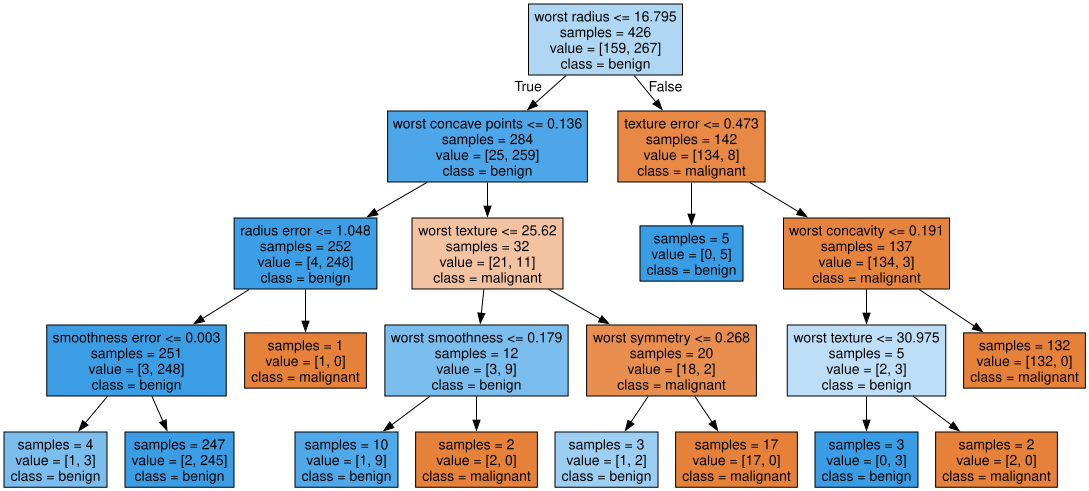

In [33]:
# ===== 书 2.3.5 节：把树导出为 graphviz 并显示 =====
from sklearn.tree import export_graphviz
export_graphviz(tree, out_file="tree.dot", class_names=["malignant", "benign"],
                feature_names=cancer.feature_names, impurity=False, filled=True)

import graphviz
with open("tree.dot") as f:
    dot_graph = f.read()
graphviz.Source(dot_graph)

Feature importances:
[0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.01019737 0.04839825
 0.         0.         0.0024156  0.         0.         0.
 0.         0.         0.72682851 0.0458159  0.         0.
 0.0141577  0.         0.018188   0.1221132  0.01188548 0.        ]


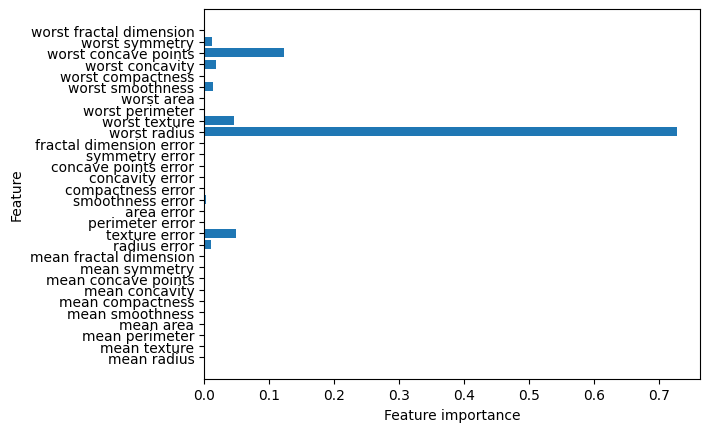

In [34]:
# ===== 书 2.3.5 节：特征重要性 =====
print("Feature importances:\n{}".format(tree.feature_importances_))

def plot_feature_importances_cancer(model):
    n_features = cancer.data.shape[1]
    plt.barh(range(n_features), model.feature_importances_, align='center')
    plt.yticks(np.arange(n_features), cancer.feature_names)
    plt.xlabel("Feature importance")
    plt.ylabel("Feature")

plot_feature_importances_cancer(tree)

Feature importances: [0. 1.]


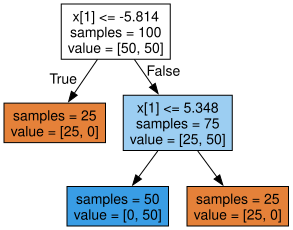

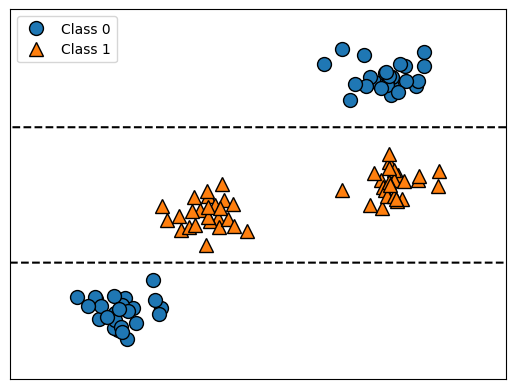

In [35]:
# ===== 书 2.3.5 节：特征与类别非单调的例子 =====
tree = mglearn.plots.plot_tree_not_monotone()
display(tree)

Text(0, 0.5, 'Price in $/Mbyte')

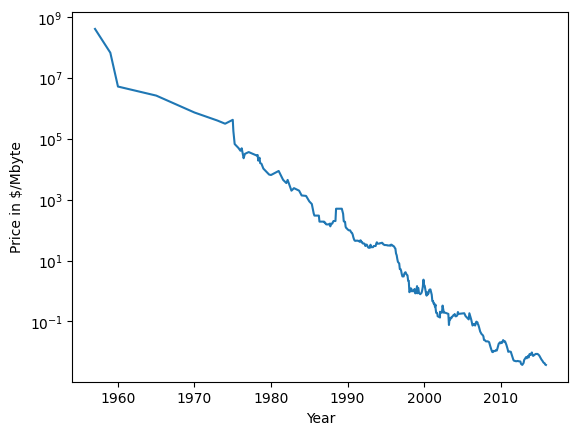

In [36]:
# ===== 书 2.3.5 节：RAM 价格数据与回归树 =====
import pandas as pd
ram_prices = pd.read_csv("data/ram_price.csv")

plt.semilogy(ram_prices.date, ram_prices.price)
plt.xlabel("Year")
plt.ylabel("Price in $/Mbyte")

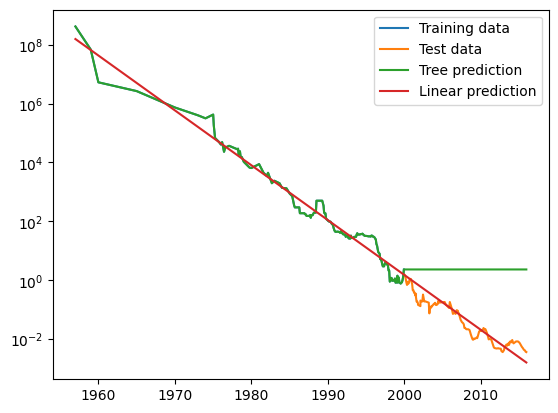

In [37]:
# ===== 书 2.3.5 节：决策树与线性回归预测 RAM 价格 =====
from sklearn.tree import DecisionTreeRegressor
# 利用历史数据预测 2000 年后的价格
data_train = ram_prices[ram_prices.date < 2000]
data_test = ram_prices[ram_prices.date >= 2000]

# 基于日期来预测价格
X_train = data_train.date.to_numpy().reshape(-1, 1)  # 版本适配：pandas 2.x 下 Series 多维索引已移除，先转 NumPy
# 利用对数变换得到数据和目标之间更简单的关系
y_train = np.log(data_train.price)

tree = DecisionTreeRegressor().fit(X_train, y_train)
linear_reg = LinearRegression().fit(X_train, y_train)

# 对所有数据进行预测
X_all = ram_prices.date.to_numpy().reshape(-1, 1)  # 版本适配：pandas 2.x 下 Series 多维索引已移除，先转 NumPy

pred_tree = tree.predict(X_all)
pred_lr = linear_reg.predict(X_all)

# 对数变换逆运算
price_tree = np.exp(pred_tree)
price_lr = np.exp(pred_lr)

plt.semilogy(data_train.date, data_train.price, label="Training data")
plt.semilogy(data_test.date, data_test.price, label="Test data")
plt.semilogy(ram_prices.date, price_tree, label="Tree prediction")
plt.semilogy(ram_prices.date, price_lr, label="Linear prediction")
plt.legend()

### 2.3.6 决策树集成

**集成（ensemble）** 是合并多个机器学习模型来构建更强大模型的方法。已证明有两种集成模型对大量分类和回归数据集都有效，二者都以决策树为基础：**随机森林（random forest）** 和**梯度提升决策树（gradient boosted decision tree）**。

In [38]:
# ===== 书 2.3.6 节：5 棵树的随机森林 =====
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=100, noise=0.25, random_state=3)
X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y,
                                                    random_state=42)

forest = RandomForestClassifier(n_estimators=5, random_state=2)
forest.fit(X_train, y_train)

,n_estimators,5
,criterion,'gini'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


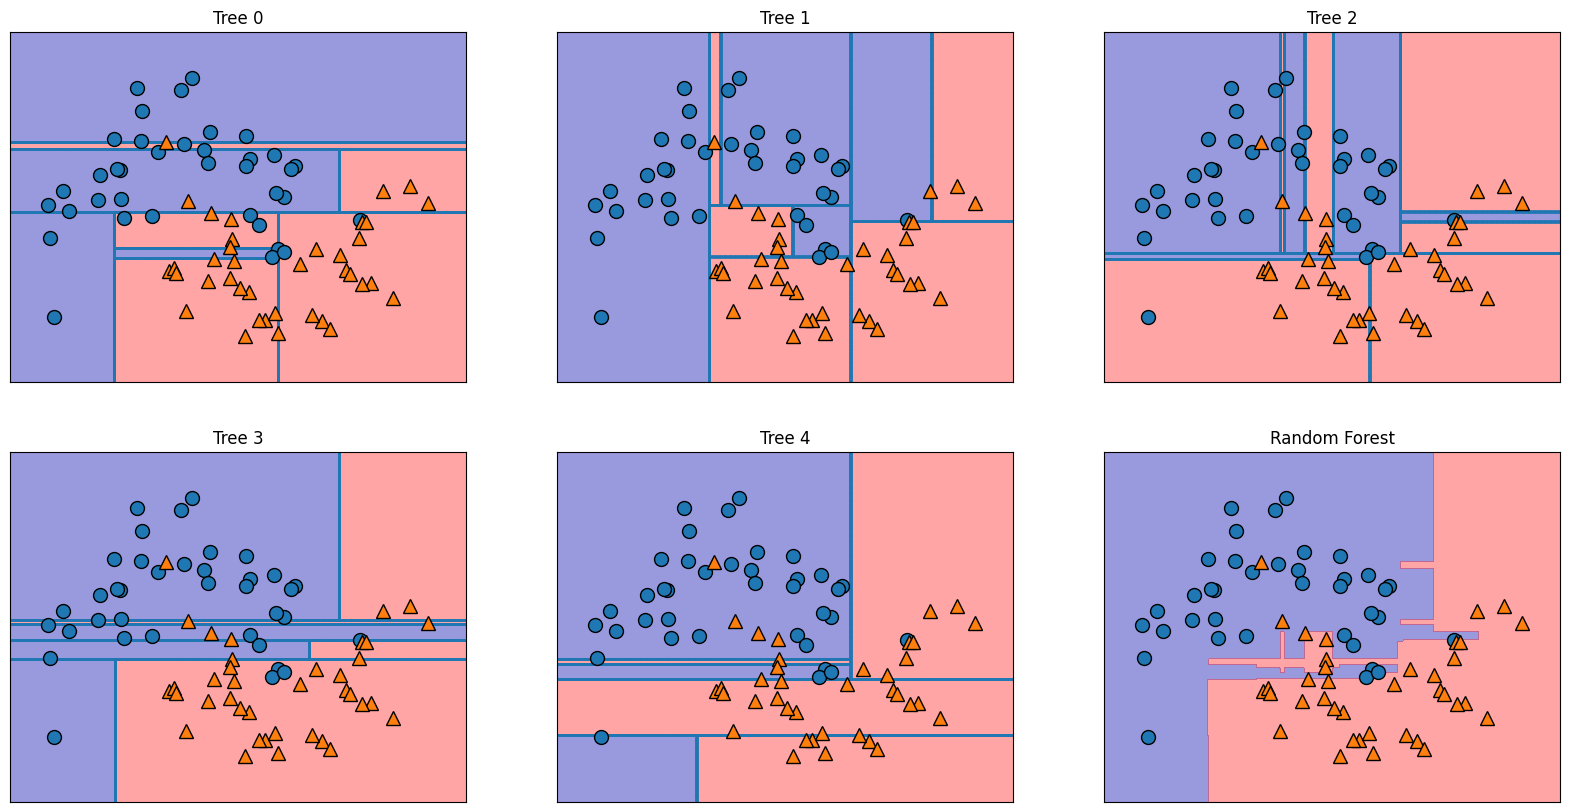

In [39]:
# ===== 书 2.3.6 节：可视化每棵树与整个森林的决策边界 =====
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
for i, (ax, tree) in enumerate(zip(axes.ravel(), forest.estimators_)):
    ax.set_title("Tree {}".format(i))
    mglearn.plots.plot_tree_partition(X_train, y_train, tree, ax=ax)

mglearn.plots.plot_2d_separator(forest, X_train, fill=True, ax=axes[-1, -1],
                                alpha=.4)
axes[-1, -1].set_title("Random Forest")
mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train)

In [40]:
# ===== 书 2.3.6 节：乳腺癌数据集上的随机森林 =====
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=0)
forest = RandomForestClassifier(n_estimators=100, random_state=0)
forest.fit(X_train, y_train)

print("Accuracy on training set: {:.3f}".format(forest.score(X_train, y_train)))
print("Accuracy on test set: {:.3f}".format(forest.score(X_test, y_test)))

Accuracy on training set: 1.000
Accuracy on test set: 0.972


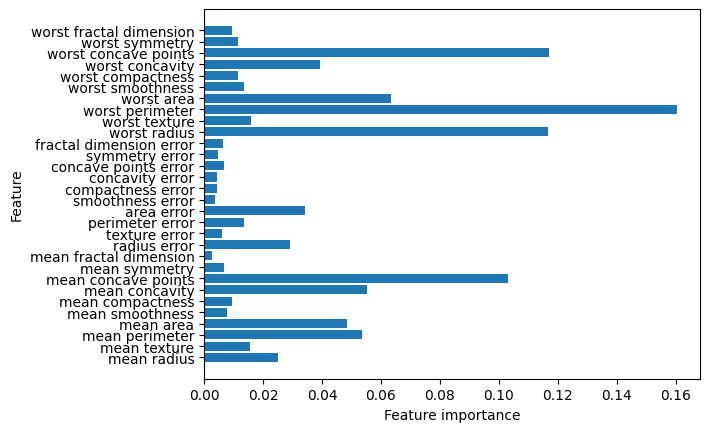

In [41]:
# ===== 书 2.3.6 节：随机森林的特征重要性（图 2-34） =====
plot_feature_importances_cancer(forest)

In [42]:
# ===== 书 2.3.6 节：GradientBoostingClassifier 默认参数 =====
from sklearn.ensemble import GradientBoostingClassifier

X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=0)

gbrt = GradientBoostingClassifier(random_state=0)   # 默认 100 棵树、深度 3、学习率 0.1
gbrt.fit(X_train, y_train)
print("默认:        train {:.3f} / test {:.3f}".format(
      gbrt.score(X_train, y_train), gbrt.score(X_test, y_test)))

gbrt = GradientBoostingClassifier(random_state=0, max_depth=1)
gbrt.fit(X_train, y_train)
print("max_depth=1: train {:.3f} / test {:.3f}".format(
      gbrt.score(X_train, y_train), gbrt.score(X_test, y_test)))

gbrt = GradientBoostingClassifier(random_state=0, learning_rate=0.01)
gbrt.fit(X_train, y_train)
print("lr=0.01:     train {:.3f} / test {:.3f}".format(
      gbrt.score(X_train, y_train), gbrt.score(X_test, y_test)))

默认:        train 1.000 / test 0.965


max_depth=1: train 0.991 / test 0.972


lr=0.01:     train 0.988 / test 0.958


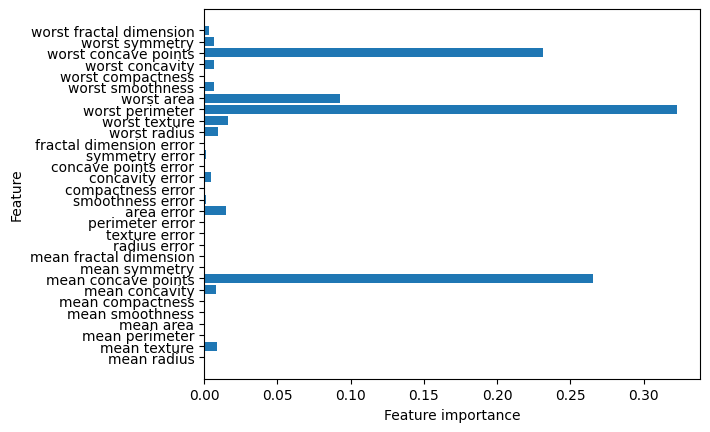

In [43]:
# ===== 书 2.3.6 节：梯度提升的特征重要性 =====
gbrt = GradientBoostingClassifier(random_state=0, max_depth=1)
gbrt.fit(X_train, y_train)

plot_feature_importances_cancer(gbrt)

### 2.3.7 核支持向量机

下一种模型是**核支持向量机（kernelized support vector machine）**。2.3.3 节研究过线性 SVM；核支持向量机（通常简称 SVM）是可以推广到更复杂模型的扩展，这些模型无法被输入空间的超平面定义。SVM 可以同时用于分类和回归，本书只介绍分类（实现于 `SVC`），类似概念也适用于支持向量回归（`SVR`）。核 SVM 背后的数学较复杂（超出了本书范围，可读 Hastie、Tibshirani 和 Friedman 的《统计学习基础》第 12 章），但它的**理念**完全可以讲清楚。

Text(0, 0.5, 'Feature 1')

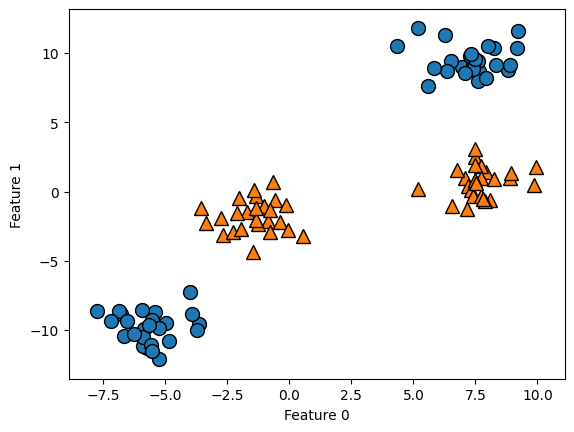

In [44]:
# ===== 书 2.3.7 节：线性不可分的二分类数据集 =====
X, y = make_blobs(centers=4, random_state=8)
y = y % 2   # 把 4 类的标签对 2 取模，变成二分类

mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

Text(0, 0.5, 'Feature 1')

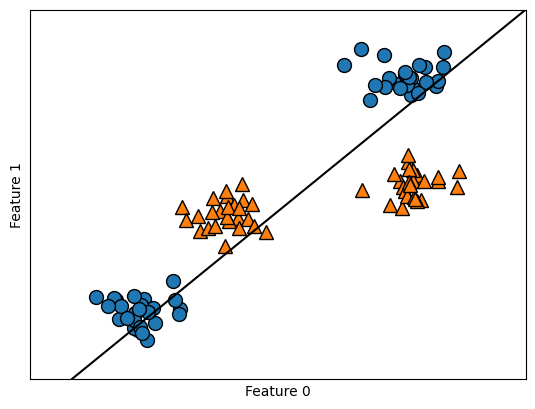

In [45]:
# ===== 书 2.3.7 节：线性 SVM 的直线边界 =====
from sklearn.svm import LinearSVC
linear_svm = LinearSVC().fit(X, y)

mglearn.plots.plot_2d_separator(linear_svm, X)
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

In [46]:
# ===== 书 2.3.7 节：三维特征扩展与 3D 可视化 =====
# 添加第二个特征的平方，作为一个新特征
X_new = np.hstack([X, X[:, 1:] ** 2])

from mpl_toolkits.mplot3d import Axes3D, axes3d
figure = plt.figure()
# 3D 可视化
ax = Axes3D(figure, elev=-152, azim=-26)
# 首先画出所有 y == 0 的点，然后画出所有 y == 1 的点
mask = y == 0
ax.scatter(X_new[mask, 0], X_new[mask, 1], X_new[mask, 2], c='b',
           cmap=mglearn.cm2, s=60)
ax.scatter(X_new[~mask, 0], X_new[~mask, 1], X_new[~mask, 2], c='r', marker='^',
           cmap=mglearn.cm2, s=60)
ax.set_xlabel("feature0")
ax.set_ylabel("feature1")
ax.set_zlabel("feature1 ** 2")

C:\Users\17272\AppData\Local\Temp\ipykernel_18656\316846476.py:11: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(X_new[mask, 0], X_new[mask, 1], X_new[mask, 2], c='b',
C:\Users\17272\AppData\Local\Temp\ipykernel_18656\316846476.py:13: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(X_new[~mask, 0], X_new[~mask, 1], X_new[~mask, 2], c='r', marker='^',


Text(0.5, 0, 'feature1 ** 2')

<Figure size 640x480 with 0 Axes>

In [47]:
# ===== 书 2.3.7 节：三维空间中的线性决策平面 =====
linear_svm_3d = LinearSVC().fit(X_new, y)
coef, intercept = linear_svm_3d.coef_.ravel(), linear_svm_3d.intercept_

# 显示线性决策边界
figure = plt.figure()
ax = Axes3D(figure, elev=-152, azim=-26)
xx = np.linspace(X_new[:, 0].min() - 2, X_new[:, 0].max() + 2, 50)
yy = np.linspace(X_new[:, 1].min() - 2, X_new[:, 1].max() + 2, 50)

XX, YY = np.meshgrid(xx, yy)
ZZ = (coef[0] * XX + coef[1] * YY + intercept) / -coef[2]
ax.plot_surface(XX, YY, ZZ, rstride=8, cstride=8, alpha=0.3)
ax.scatter(X_new[mask, 0], X_new[mask, 1], X_new[mask, 2], c='b',
           cmap=mglearn.cm2, s=60)
ax.scatter(X_new[~mask, 0], X_new[~mask, 1], X_new[~mask, 2], c='r', marker='^',
           cmap=mglearn.cm2, s=60)
ax.set_xlabel("feature0")
ax.set_ylabel("feature1")
ax.set_zlabel("feature1 ** 2")

C:\Users\17272\AppData\Local\Temp\ipykernel_18656\427819154.py:14: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(X_new[mask, 0], X_new[mask, 1], X_new[mask, 2], c='b',
C:\Users\17272\AppData\Local\Temp\ipykernel_18656\427819154.py:16: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(X_new[~mask, 0], X_new[~mask, 1], X_new[~mask, 2], c='r', marker='^',


Text(0.5, 0, 'feature1 ** 2')

<Figure size 640x480 with 0 Axes>

Text(0, 0.5, 'Feature 1')

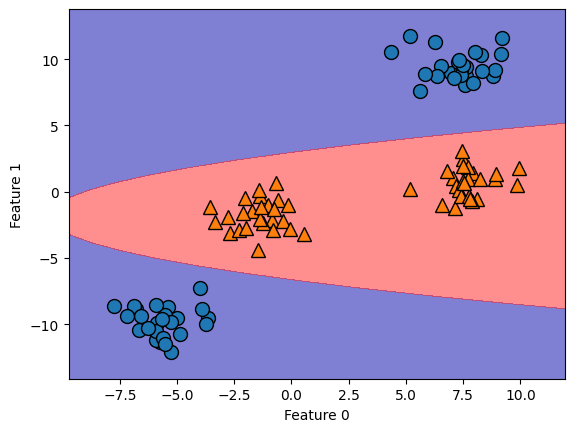

In [48]:
# ===== 书 2.3.7 节：把三维边界投回二维 =====
ZZ = YY ** 2
dec = linear_svm_3d.decision_function(np.c_[XX.ravel(), YY.ravel(), ZZ.ravel()])
plt.contourf(XX, YY, dec.reshape(XX.shape), levels=[dec.min(), 0, dec.max()],
             cmap=mglearn.cm2, alpha=0.5)
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

Text(0, 0.5, 'Feature 1')

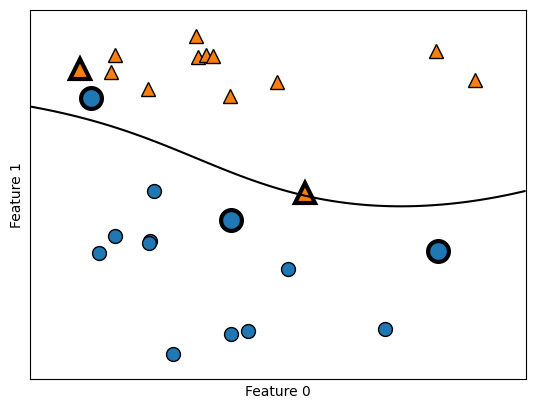

In [49]:
# ===== 书 2.3.7 节：RBF 核 SVM 的决策边界与支持向量 =====
from sklearn.svm import SVC
X, y = mglearn.tools.make_handcrafted_dataset()
svm = SVC(kernel='rbf', C=10, gamma=0.1).fit(X, y)
mglearn.plots.plot_2d_separator(svm, X, eps=.5)
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
# 画出支持向量
sv = svm.support_vectors_
# 支持向量的类别标签由 dual_coef_ 的正负号给出
sv_labels = svm.dual_coef_.ravel() > 0
mglearn.discrete_scatter(sv[:, 0], sv[:, 1], sv_labels, s=15, markeredgewidth=3)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

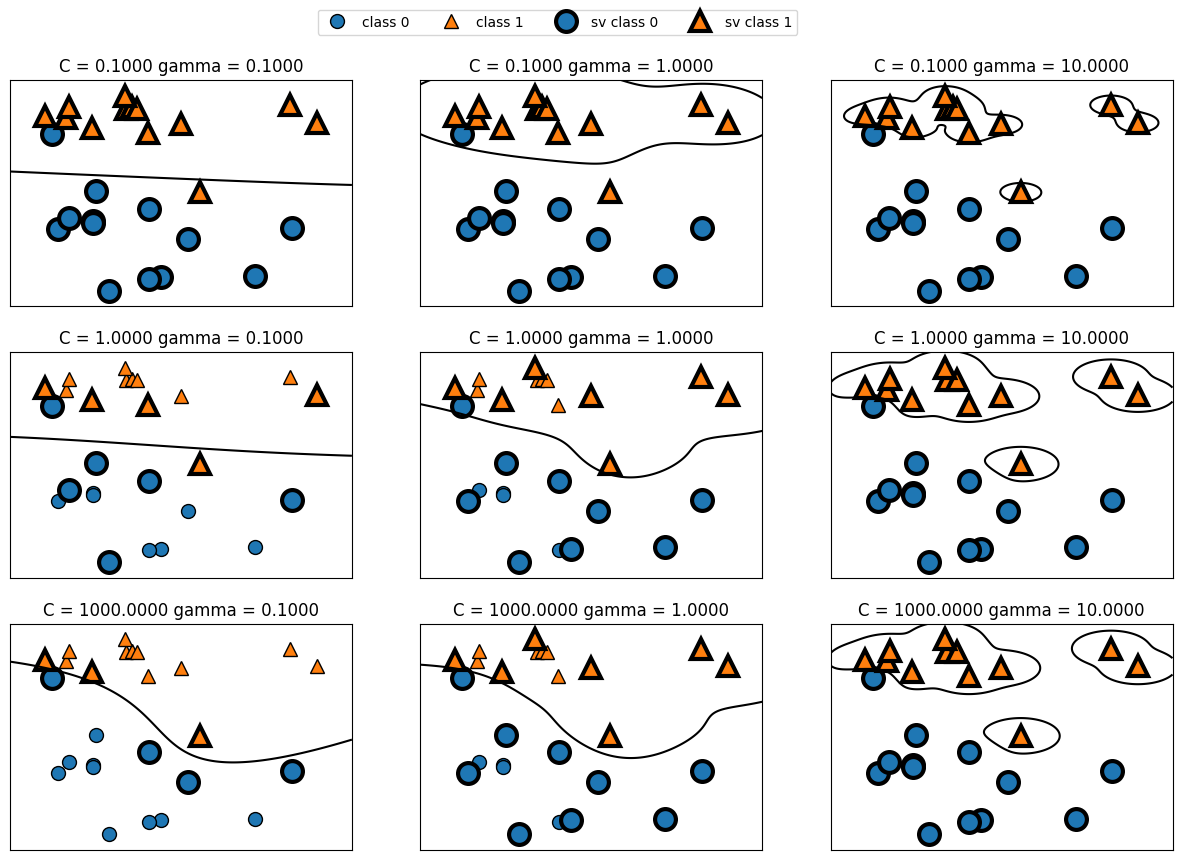

In [50]:
# ===== 书 2.3.7 节：C 与 gamma 的 3x3 网格 =====
fig, axes = plt.subplots(3, 3, figsize=(15, 10))

for ax, C in zip(axes, [-1, 0, 3]):
    for a, gamma in zip(ax, range(-1, 2)):
        mglearn.plots.plot_svm(log_C=C, log_gamma=gamma, ax=a)

axes[0, 0].legend(["class 0", "class 1", "sv class 0", "sv class 1"],
                  ncol=4, loc=(.9, 1.2))

In [51]:
# ===== 书 2.3.7 节：未缩放数据上的 SVC =====
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=0)

svc = SVC()
svc.fit(X_train, y_train)

print("Accuracy on training set: {:.2f}".format(svc.score(X_train, y_train)))
print("Accuracy on test set: {:.2f}".format(svc.score(X_test, y_test)))

Accuracy on training set: 0.90
Accuracy on test set: 0.94


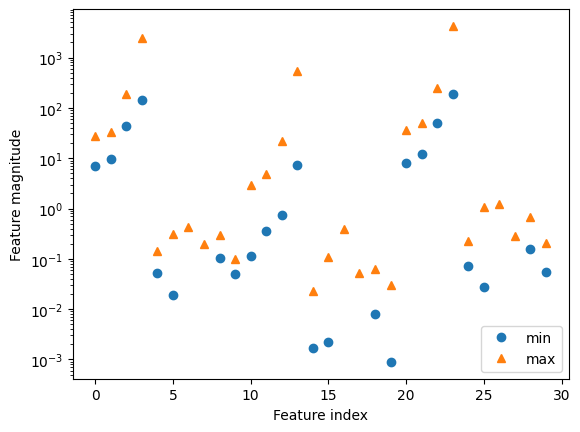

In [52]:
# ===== 书 2.3.7 节：乳腺癌数据集的特征范围 =====
plt.plot(X_train.min(axis=0), 'o', label="min")
plt.plot(X_train.max(axis=0), '^', label="max")
plt.legend(loc=4)
plt.xlabel("Feature index")
plt.ylabel("Feature magnitude")
plt.yscale("log")

In [53]:
# ===== 书 2.3.7 节：人工 MinMax 缩放 =====
# 计算训练集中每个特征的最小值
min_on_training = X_train.min(axis=0)
# 计算训练集中每个特征的范围（最大值-最小值）
range_on_training = (X_train - min_on_training).max(axis=0)

# 减去最小值，然后除以范围：每个特征都是 min=0、max=1
X_train_scaled = (X_train - min_on_training) / range_on_training
# 利用训练集的最小值和范围对测试集做相同的变换（详见第 3 章）
X_test_scaled = (X_test - min_on_training) / range_on_training

svc = SVC()
svc.fit(X_train_scaled, y_train)
print("缩放后:  train {:.3f} / test {:.3f}".format(
      svc.score(X_train_scaled, y_train), svc.score(X_test_scaled, y_test)))

svc = SVC(C=1000)
svc.fit(X_train_scaled, y_train)
print("C=1000:  train {:.3f} / test {:.3f}".format(
      svc.score(X_train_scaled, y_train), svc.score(X_test_scaled, y_test)))

缩放后:  train 0.984 / test 0.972
C=1000:  train 1.000 / test 0.958


### 2.3.8 神经网络（深度学习）

一类被称为**神经网络（neural network）** 的算法最近以"深度学习"的名字再度流行。深度学习算法往往经过精确调整，只适用于特定的使用场景；本节讨论相对简单的方法——用于分类和回归的**多层感知机（multilayer perceptron，MLP）**，它可以作为研究更复杂的深度学习方法的起点。MLP 也被称为（普通）**前馈神经网络（feed-forward neural network）**，有时简称神经网络。

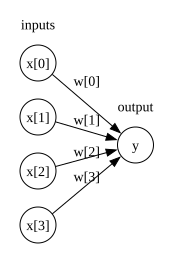

In [54]:
# ===== 书 2.3.8 节：Logistic 回归的图示 =====
display(mglearn.plots.plot_logistic_regression_graph())

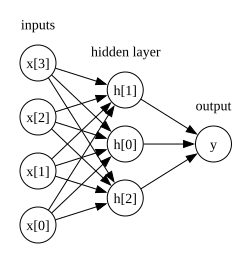

In [55]:
# ===== 书 2.3.8 节：单隐层 MLP 图示 =====
display(mglearn.plots.plot_single_hidden_layer_graph())

Text(0, 0.5, 'relu(x), tanh(x)')

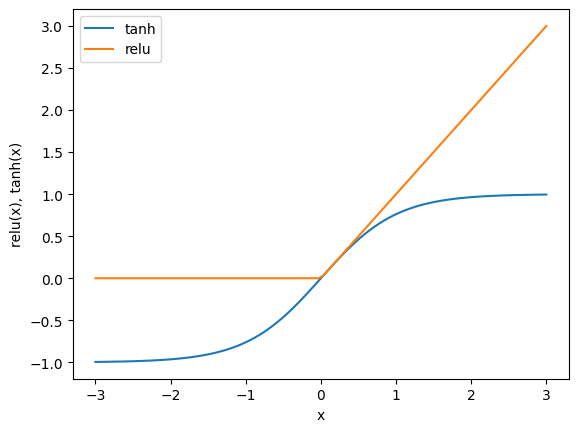

In [56]:
# ===== 书 2.3.8 节：tanh 与 relu 激活函数 =====
line = np.linspace(-3, 3, 100)
plt.plot(line, np.tanh(line), label="tanh")
plt.plot(line, np.maximum(line, 0), label="relu")
plt.legend(loc="best")
plt.xlabel("x")
plt.ylabel("relu(x), tanh(x)")

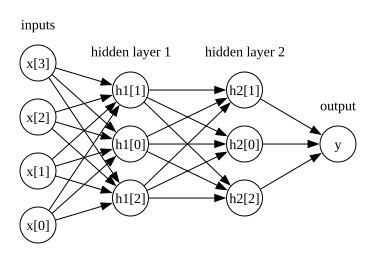

In [57]:
# ===== 书 2.3.8 节：两个隐层的 MLP 图示 =====
mglearn.plots.plot_two_hidden_layer_graph()

Text(0, 0.5, 'Feature 1')

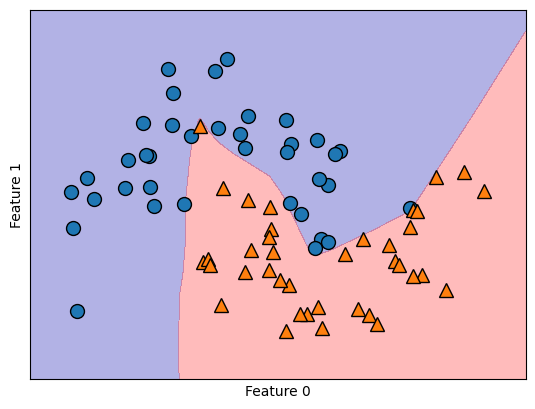

In [58]:
# ===== 书 2.3.8 节：100 个隐单元的 MLP =====
from sklearn.neural_network import MLPClassifier
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=100, noise=0.25, random_state=3)

X_train, X_test, y_train, y_test = train_test_split(X, y, stratify=y,
                                                    random_state=42)

mlp = MLPClassifier(solver='lbfgs', random_state=0).fit(X_train, y_train)
mglearn.plots.plot_2d_separator(mlp, X_train, fill=True, alpha=.3)
mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train)
plt.xlabel("Feature 0")
plt.ylabel("Feature 1")

In [59]:
# ===== 书 2.3.8 节：10 个隐单元 / 2 个隐层 / tanh =====
mlp = MLPClassifier(solver='lbfgs', random_state=0, hidden_layer_sizes=[10])
mlp.fit(X_train, y_train)

# 使用 2 个隐层，每个包含 10 个单元
mlp = MLPClassifier(solver='lbfgs', random_state=0,
                    hidden_layer_sizes=[10, 10])
mlp.fit(X_train, y_train)

# 使用 2 个隐层，每个包含 10 个单元，这次使用 tanh 非线性
mlp = MLPClassifier(solver='lbfgs', activation='tanh',
                    random_state=0, hidden_layer_sizes=[10, 10])
mlp.fit(X_train, y_train)

C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:601: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:601: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


,hidden_layer_sizes,"[10, 10]"
,activation,'tanh'
,solver,'lbfgs'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,200
,shuffle,True
,random_state,0


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:601: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:601: ConvergenceWarning: lbfgs failed to converge after 200 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=200).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


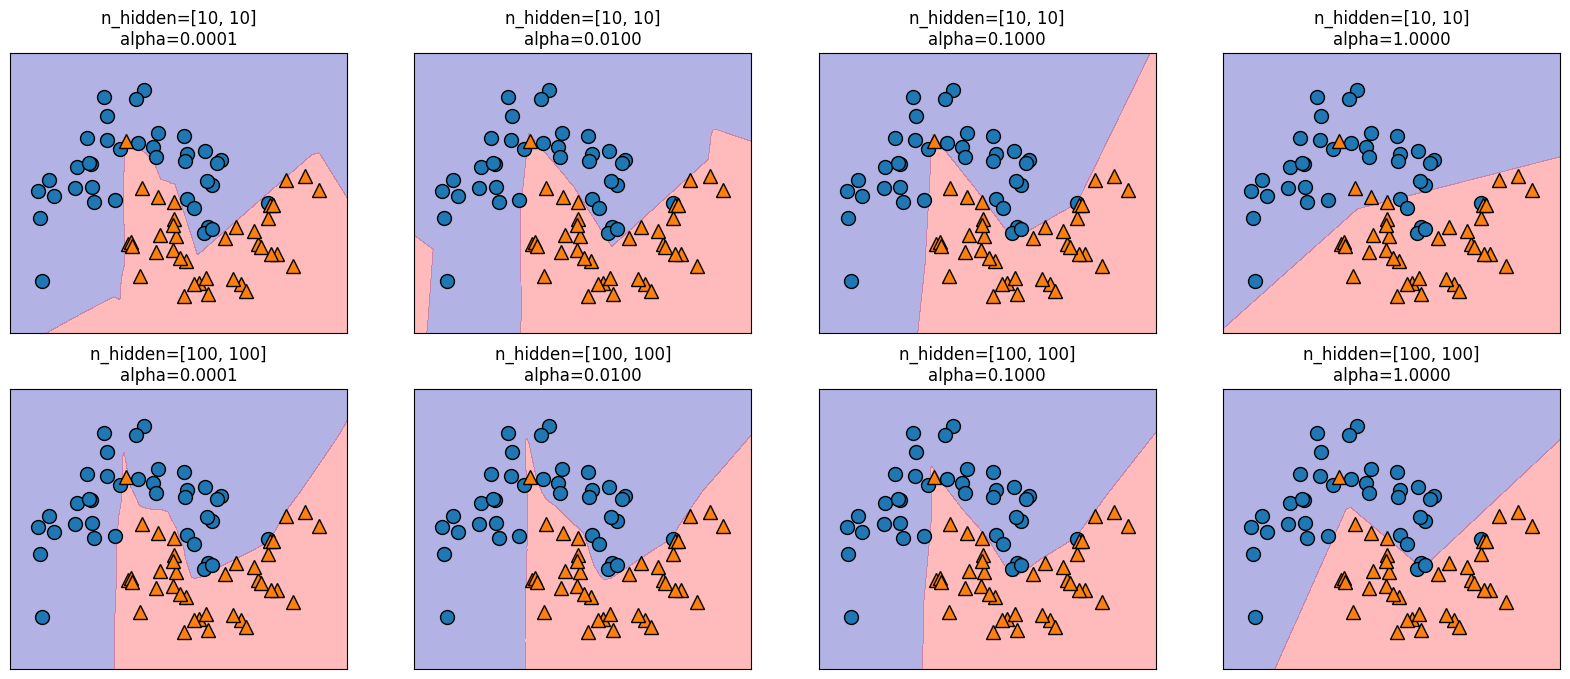

In [60]:
# ===== 书 2.3.8 节：隐单元个数与 alpha 的组合网格 =====
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for axx, n_hidden_nodes in zip(axes, [10, 100]):
    for ax, alpha in zip(axx, [0.0001, 0.01, 0.1, 1]):
        mlp = MLPClassifier(solver='lbfgs', random_state=0,
                            hidden_layer_sizes=[n_hidden_nodes, n_hidden_nodes],
                            alpha=alpha)
        mlp.fit(X_train, y_train)
        mglearn.plots.plot_2d_separator(mlp, X_train, fill=True, alpha=.3, ax=ax)
        mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train, ax=ax)
        ax.set_title("n_hidden=[{}, {}]\nalpha={:.4f}".format(
                      n_hidden_nodes, n_hidden_nodes, alpha))

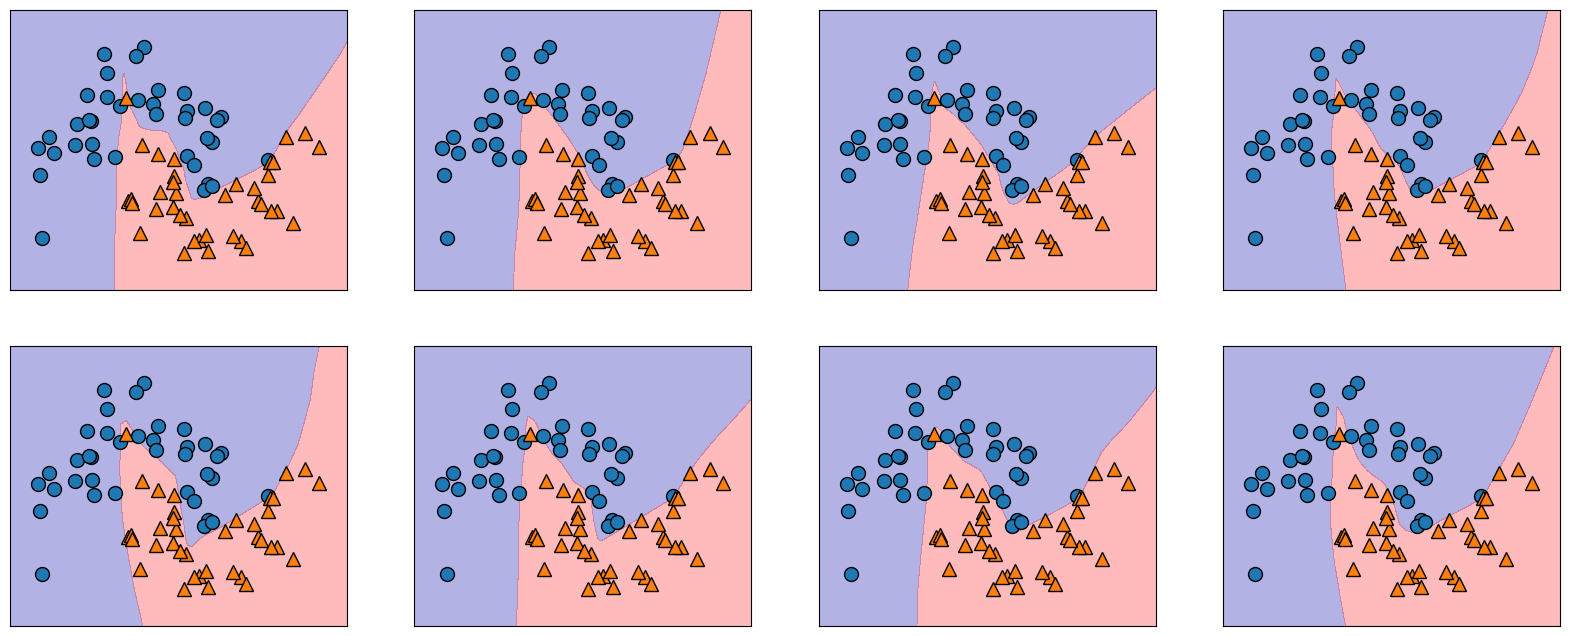

In [61]:
# ===== 书 2.3.8 节：相同参数、不同随机初始化 =====
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for i, ax in enumerate(axes.ravel()):
    mlp = MLPClassifier(solver='lbfgs', random_state=i,
                        hidden_layer_sizes=[100, 100])
    mlp.fit(X_train, y_train)
    mglearn.plots.plot_2d_separator(mlp, X_train, fill=True, alpha=.3, ax=ax)
    mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train, ax=ax)

In [62]:
# ===== 书 2.3.8 节：未缩放数据上的 MLP =====
X_train, X_test, y_train, y_test = train_test_split(
    cancer.data, cancer.target, random_state=0)

mlp = MLPClassifier(random_state=42)
mlp.fit(X_train, y_train)

print("Accuracy on training set: {:.2f}".format(mlp.score(X_train, y_train)))
print("Accuracy on test set: {:.2f}".format(mlp.score(X_test, y_test)))

Accuracy on training set: 0.94
Accuracy on test set: 0.92


In [63]:
# ===== 书 2.3.8 节：人工标准化后再训练 MLP =====
# 计算训练集中每个特征的平均值
mean_on_train = X_train.mean(axis=0)
# 计算训练集中每个特征的标准差
std_on_train = X_train.std(axis=0)

# 减去平均值，然后乘以标准差的倒数：mean=0，std=1
X_train_scaled = (X_train - mean_on_train) / std_on_train
# 对测试集做相同的变换（使用训练集的平均值和标准差）
X_test_scaled = (X_test - mean_on_train) / std_on_train

mlp = MLPClassifier(random_state=0)
mlp.fit(X_train_scaled, y_train)

print("Accuracy on training set: {:.3f}".format(
    mlp.score(X_train_scaled, y_train)))
print("Accuracy on test set: {:.3f}".format(mlp.score(X_test_scaled, y_test)))

Accuracy on training set: 0.991
Accuracy on test set: 0.965


C:\Anocanda\envs\machinelearn\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:780: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


In [64]:
# ===== 书 2.3.8 节：增大 max_iter 与 alpha =====
mlp = MLPClassifier(max_iter=1000, random_state=0)
mlp.fit(X_train_scaled, y_train)
print("max_iter=1000: train {:.3f} / test {:.3f}".format(
      mlp.score(X_train_scaled, y_train), mlp.score(X_test_scaled, y_test)))

mlp = MLPClassifier(max_iter=1000, alpha=1, random_state=0)
mlp.fit(X_train_scaled, y_train)
print("alpha=1:       train {:.3f} / test {:.3f}".format(
      mlp.score(X_train_scaled, y_train), mlp.score(X_test_scaled, y_test)))

max_iter=1000: train 1.000 / test 0.972


alpha=1:       train 0.988 / test 0.972


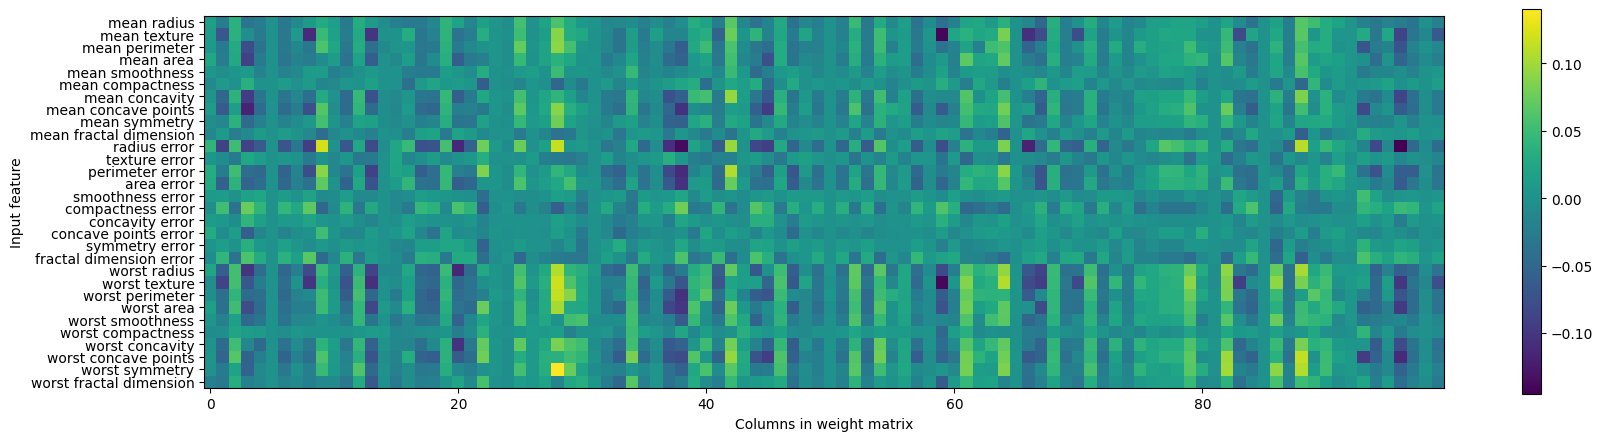

In [65]:
# ===== 书 2.3.8 节：第一个隐层权重的热图 =====
plt.figure(figsize=(20, 5))
plt.imshow(mlp.coefs_[0], interpolation='none', cmap='viridis')
plt.yticks(range(30), cancer.feature_names)
plt.xlabel("Columns in weight matrix")
plt.ylabel("Input feature")
plt.colorbar()

## 2.4 分类器的不确定度估计

scikit-learn 接口还有一个有用之处：**分类器能够给出预测的不确定度估计**。我们感兴趣的不仅是分类器预测测试点属于哪个类别，还有它对这个预测的**置信程度**。在实践中，不同类型的错误会导致非常不同的结果：想象一个用于测试癌症的医疗应用——假阳性预测可能只是让患者接受额外的测试，假阴性预测却可能导致重病没有得到治疗（第 5 章进一步探讨这一主题）。

In [66]:
# ===== 书 2.4 节：构造带字符串类别名的二分类任务 =====
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.datasets import make_circles
X, y = make_circles(noise=0.25, factor=0.5, random_state=1)

# 为了便于说明，我们将两个类别重命名为 "blue" 和 "red"
y_named = np.array(["blue", "red"])[y]

# 我们可以对任意个数组调用 train_test_split，所有数组的划分方式都是一致的
X_train, X_test, y_train_named, y_test_named, y_train, y_test = \
    train_test_split(X, y_named, y, random_state=0)

# 构建梯度提升模型
gbrt = GradientBoostingClassifier(random_state=0)
gbrt.fit(X_train, y_train_named)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


### 2.4.1 决策函数

二分类情况下，`decision_function` 返回值形状是 \((n_{samples},)\)，为每个样本返回一个浮点数：

In [67]:
# ===== 书 2.4.1 节：decision_function 的形状与含义 =====
print("X_test.shape: {}".format(X_test.shape))
print("Decision function shape: {}".format(
    gbrt.decision_function(X_test).shape))

# 显示 decision_function 的前几个元素
print("Decision function:\n{}".format(gbrt.decision_function(X_test)[:6]))

X_test.shape: (25, 2)
Decision function shape: (25,)
Decision function:
[ 4.13592603 -1.70169917 -3.95106099 -3.62609552  4.28986642  3.66166081]


In [68]:
# ===== 书 2.4.1 节：用符号还原 predict，以及 classes_ 的角色 =====
print("Thresholded decision function:\n{}".format(
    gbrt.decision_function(X_test) > 0))
print("Predictions:\n{}".format(gbrt.predict(X_test)))

# 将布尔值 True/False 转换成 0 和 1
greater_zero = (gbrt.decision_function(X_test) > 0).astype(int)
# 利用 0 和 1 作为 classes_ 的索引
pred = gbrt.classes_[greater_zero]
print("pred is equal to predictions: {}".format(
    np.all(pred == gbrt.predict(X_test))))

decision_function = gbrt.decision_function(X_test)
print("Decision function minimum: {:.2f} maximum: {:.2f}".format(
    np.min(decision_function), np.max(decision_function)))

Thresholded decision function:
[ True False False False  True  True False  True  True  True False  True
  True False  True False False False  True  True  True  True  True False
 False]
Predictions:
['red' 'blue' 'blue' 'blue' 'red' 'red' 'blue' 'red' 'red' 'red' 'blue'
 'red' 'red' 'blue' 'red' 'blue' 'blue' 'blue' 'red' 'red' 'red' 'red'
 'red' 'blue' 'blue']
pred is equal to predictions: True
Decision function minimum: -7.69 maximum: 4.29


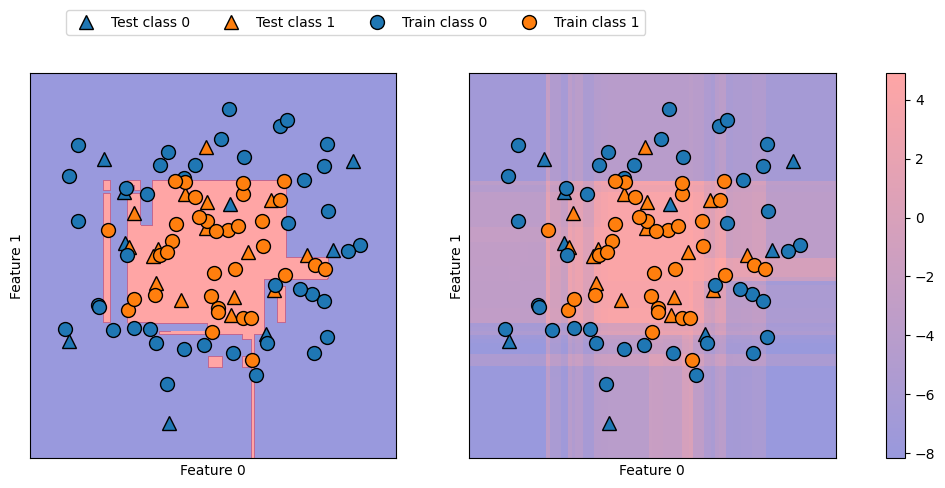

In [69]:
# ===== 书 2.4.1 节：决策边界（左）与决策函数（右） =====
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
mglearn.tools.plot_2d_separator(gbrt, X, ax=axes[0], alpha=.4,
                                fill=True, cm=mglearn.cm2)
scores_image = mglearn.tools.plot_2d_scores(gbrt, X, ax=axes[1],
                                            alpha=.4, cm=mglearn.ReBl)

for ax in axes:
    # 画出训练点和测试点
    mglearn.discrete_scatter(X_test[:, 0], X_test[:, 1], y_test,
                             markers='^', ax=ax)
    mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train,
                             markers='o', ax=ax)
    ax.set_xlabel("Feature 0")
    ax.set_ylabel("Feature 1")
cbar = plt.colorbar(scores_image, ax=axes.tolist())
axes[0].legend(["Test class 0", "Test class 1", "Train class 0",
                "Train class 1"], ncol=4, loc=(.1, 1.1))

### 2.4.2 预测概率

`predict_proba` 的输出是**每个类别的概率**，通常比 decision_function 的输出更容易理解。二分类问题中它的形状始终是 \((n_{samples}, 2)\)：

In [70]:
# ===== 书 2.4.2 节：predict_proba 的形状与数值 =====
print("Shape of probabilities: {}".format(gbrt.predict_proba(X_test).shape))
# 显示 predict_proba 的前几个元素
print("Predicted probabilities:\n{}".format(
    gbrt.predict_proba(X_test[:6])))

Shape of probabilities: (25, 2)
Predicted probabilities:
[[0.01573626 0.98426374]
 [0.84575653 0.15424347]
 [0.98112869 0.01887131]
 [0.97407033 0.02592967]
 [0.01352142 0.98647858]
 [0.02504637 0.97495363]]


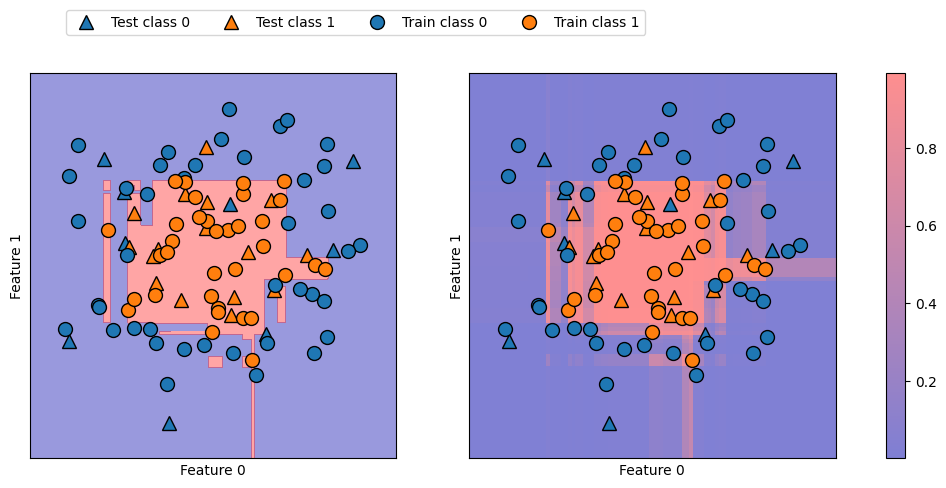

In [71]:
# ===== 书 2.4.2 节：决策边界（左）与预测概率（右） =====
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

mglearn.tools.plot_2d_separator(
    gbrt, X, ax=axes[0], alpha=.4, fill=True, cm=mglearn.cm2)
scores_image = mglearn.tools.plot_2d_scores(
    gbrt, X, ax=axes[1], alpha=.5, cm=mglearn.ReBl, function='predict_proba')

for ax in axes:
    mglearn.discrete_scatter(X_test[:, 0], X_test[:, 1], y_test,
                             markers='^', ax=ax)
    mglearn.discrete_scatter(X_train[:, 0], X_train[:, 1], y_train,
                             markers='o', ax=ax)
    ax.set_xlabel("Feature 0")
    ax.set_ylabel("Feature 1")
cbar = plt.colorbar(scores_image, ax=axes.tolist())
axes[0].legend(["Test class 0", "Test class 1", "Train class 0",
                "Train class 1"], ncol=4, loc=(.1, 1.1))

### 2.4.3 多分类问题的不确定度

decision_function 和 predict_proba 也适用于多分类。对鸢尾花（Iris）三分类数据集应用：

In [72]:
# ===== 书 2.4.3 节：多分类的 decision_function =====
from sklearn.datasets import load_iris

iris = load_iris()
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, random_state=42)

gbrt = GradientBoostingClassifier(learning_rate=0.01, random_state=0)
gbrt.fit(X_train, y_train)

print("Decision function shape: {}".format(gbrt.decision_function(X_test).shape))
print("Decision function:\n{}".format(gbrt.decision_function(X_test)[:6, :]))

Decision function shape: (38, 3)
Decision function:
[[-0.89604809  1.14724958 -0.82754003]
 [ 1.16113086 -0.80789044 -0.82827067]
 [-0.89091511 -0.77671169  1.19653416]
 [-0.89604809  1.14724958 -0.82754003]
 [-0.89763468  0.96497584 -0.10374792]
 [ 1.16113086 -0.80789044 -0.82827067]]


In [73]:
# ===== 书 2.4.3 节：用 argmax 还原多分类预测 =====
print("Argmax of decision function:\n{}".format(
      np.argmax(gbrt.decision_function(X_test), axis=1)))
print("Predictions:\n{}".format(gbrt.predict(X_test)))

# predict_proba 形状相同，每行概率之和为 1
print("Predicted probabilities:\n{}".format(gbrt.predict_proba(X_test)[:6]))
print("Sums: {}".format(gbrt.predict_proba(X_test)[:6].sum(axis=1)))

Argmax of decision function:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0]
Predictions:
[1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0 0 0 1 0 0 2 1
 0]
Predicted probabilities:
[[0.10217718 0.78840034 0.10942248]
 [0.78347147 0.10936745 0.10716108]
 [0.09818072 0.11005864 0.79176065]
 [0.10217718 0.78840034 0.10942248]
 [0.10360005 0.66723901 0.22916094]
 [0.78347147 0.10936745 0.10716108]]
Sums: [1. 1. 1. 1. 1. 1.]


In [74]:
# ===== 书 2.4.3 节：字符串类别名时用 classes_ 对齐 =====
logreg = LogisticRegression()

# 用 Iris 数据集的类别名称来表示每一个目标值
named_target = iris.target_names[y_train]
logreg.fit(X_train, named_target)
print("unique classes in training data: {}".format(logreg.classes_))
print("predictions: {}".format(logreg.predict(X_test)[:10]))
argmax_dec_func = np.argmax(logreg.decision_function(X_test), axis=1)
print("argmax of decision function: {}".format(argmax_dec_func[:10]))
print("argmax combined with classes_: {}".format(
        logreg.classes_[argmax_dec_func][:10]))

unique classes in training data: ['setosa' 'versicolor' 'virginica']
predictions: ['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor']
argmax of decision function: [1 0 2 1 1 0 1 2 1 1]
argmax combined with classes_: ['versicolor' 'setosa' 'virginica' 'versicolor' 'versicolor' 'setosa'
 'versicolor' 'virginica' 'versicolor' 'versicolor']


## 2.5 小结与展望

本章先讨论了模型复杂度与泛化（学习一个能在前所未见的新数据上表现良好的模型），由此引出欠拟合（模型无法获取训练数据中的所有变化）和过拟合（模型过分关注训练数据、对新数据泛化不好）。然后讨论了一系列用于分类和回归的模型、各自的优缺点以及如何控制复杂度。对许多算法而言，**设置正确的参数对模型性能至关重要**；有些算法还对输入数据的表示方式很敏感（特别是特征缩放）。盲目把算法套在数据集上、不理解模型的假设和参数含义，不太可能得到精度高的模型。